# Software Engineering for AI Developers: Testing AI Code

> **Who is this for:** you write AI code (text cleaning, feature transformers, model wrappers, LLM calls) and want to change it without fear. You may have seen `assert` and heard of pytest, but never built a real test suite, mocked an LLM, or tested a model's *behaviour*.
>
> **What you will learn:**
> - why we test, the **testing pyramid**, unit vs. integration vs. end-to-end tests
> - writing a small package and a **real pytest suite** on disk, running it, and **reading a failure**
> - pytest features: fixtures (scopes, `tmp_path`, `conftest.py`), `parametrize`, marks (`skip`, `xfail`, custom), `raises`, `approx`
> - **mocking** LLM and HTTP calls with `unittest.mock`, and dependency injection as the alternative
> - **property-based testing** (with `hypothesis` if installed, and a pure-Python fallback)
> - testing ML specifically: **data validation**, **deterministic training** with seeds, **behavioural tests** (CheckList: minimum functionality, invariance, directional), **golden-set regression tests for prompts**, **tolerance-based assertions**
> - **coverage** (with `coverage`/`pytest-cov` if installed, and a from-scratch line tracer otherwise), **TDD** red-green-refactor, and running it all in **CI**
>
> **Prerequisites:** [01_oop_and_solid_principles.ipynb](01_oop_and_solid_principles.ipynb) (dependency injection) and [02_design_patterns_for_ai_code.ipynb](02_design_patterns_for_ai_code.ipynb). Helpful: [01_Python/04_industry_from_notebook_to_production_code.ipynb](../01_Python/04_industry_from_notebook_to_production_code.ipynb).
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, no network. Uses pytest, numpy, pandas, scikit-learn, httpx and matplotlib. `hypothesis`, `coverage` and `pytest-cov` are optional.
>
> **Optional track:** part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep.

## Explained simply

A **test** is a small piece of code that checks your real code and shouts if something breaks. It works like a smoke alarm: cheap, always on, and you are very glad of it the one time it goes off. Car makers crash-test every new model before selling it; software teams run thousands of automatic tests before every release for the same reason. AI code needs tests even more than normal code, because it often fails quietly: a broken step still produces numbers, just wrong ones, and nothing crashes. In this notebook you will write tests, run them with a tool called **pytest**, replace a real AI service with a pretend one so tests run offline and for free, and check that a model behaves sensibly.

**Tiny example.** A function `count_words("I love AI")` should return 3. The test is one line: `assert count_words("I love AI") == 3`. If someone later changes the function to split on commas instead of spaces, it returns 1, and the test immediately fails with the message `assert 1 == 3`, long before a user notices.

**In one line**

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Unit test | check one small piece on its own | does `clean_text("Hi!")` give `"hi"`? |
| Mock / fake | a stand-in actor for an expensive or unreliable service | a pretend LLM, so tests run offline and cost nothing |
| Behavioural test | check the model acts sensibly, not just its score | changing a person's name in a review must not change its sentiment |

### How this notebook fits with the rest of the repo

| Already covered | Where | What this notebook adds |
|---|---|---|
| Test functions called by hand; pytest syntax shown in comments | [01_Python/02_industrial.ipynb §5](../01_Python/02_industrial.ipynb) | a real suite on disk, run by pytest, including failures and how to read them |
| A pytest run for one refactored project (fixtures, `raises`, `monkeypatch`) | [01_Python/04 §13](../01_Python/04_industry_from_notebook_to_production_code.ipynb) | fixture **scopes**, marks, `xfail`, `conftest` options, mocks, property-based tests, coverage, TDD |
| The three testing levels for ML in a table | [22_ML_System_Design/07 §3](../22_ML_System_Design/07_software_engineering_for_ml.ipynb) | each level actually implemented, plus behavioural and golden-set tests |
| Pandera / Great Expectations, API tests with `TestClient` | [15_MLOps/07_testing_in_ml/01_testing_ml.ipynb](../15_MLOps/07_testing_in_ml/01_testing_ml.ipynb) | the *ideas* behind those tools, implemented in plain pandas |
| CI workflows | [20_Git_and_DevOps/03_github_actions_cicd.ipynb](../20_Git_and_DevOps/03_github_actions_cicd.ipynb) | which tests to run when (fast vs. slow), and how |

### Table of contents
1. Why test? The testing pyramid
2. The project under test: a small `aikit` package
3. Your first pytest run, and reading a failure
4. pytest features: fixtures, parametrize, marks, raises, approx
5. Mocking LLM and HTTP calls (and dependency injection instead)
6. Property-based testing
7. Testing ML: data validation, determinism, behavioural tests, golden sets, tolerances
8. Coverage
9. TDD: red, green, refactor
10. Continuous integration
11. The whole suite, modern-AI connections, recap and practice

In [1]:
# Setup: a temporary project folder plus two helpers to write files and run pytest in it.
import os, sys, re, json, math, time, random, shutil, hashlib, textwrap, tempfile, subprocess, importlib
from pathlib import Path
from unittest.mock import MagicMock, patch

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(0); np.random.seed(0)
WORK = Path(tempfile.mkdtemp(prefix="aikit_"))          # the whole project lives here; deleted at the end

def write(rel_path, text):
    """Write a file into the project folder (dedented), creating folders as needed."""
    p = WORK / rel_path
    p.parent.mkdir(parents=True, exist_ok=True)
    p.write_text(textwrap.dedent(text).lstrip("\n"))
    print(f"wrote {rel_path:34s} {len(p.read_text().splitlines()):3d} lines")

def run(*cmd, tail=None):
    """Run a command inside the project folder and print its (anonymised) output."""
    env = {**os.environ, "PY_COLORS": "0",                     # plain text output (no colour codes)
           "PYTEST_DISABLE_PLUGIN_AUTOLOAD": "1"}               # don't load unrelated pytest plugins
    r = subprocess.run([sys.executable, *cmd], cwd=WORK, capture_output=True, text=True, timeout=600, env=env)
    out = r.stdout + r.stderr
    for real, shown in [(str(WORK), "<project>"), (sys.prefix, "<venv>"), (str(Path.home()), "~")]:
        out = out.replace(real, shown)                    # never leak local paths into the notebook
    lines = out.rstrip().splitlines()
    print("\n".join(lines[-tail:] if tail else lines))
    print(f"[exit code {r.returncode}]")
    LAST_EXIT_CODE[0] = r.returncode                          # kept for asserts; nothing is returned

LAST_EXIT_CODE = [None]

def pytest(*args, tail=None):
    run("-m", "pytest", *args, tail=tail)

def have(module):
    """Is an optional library installed?"""
    return importlib.util.find_spec(module) is not None

HAVE_HYPOTHESIS, HAVE_COVERAGE, HAVE_PYTEST_COV = have("hypothesis"), have("coverage"), have("pytest_cov")
import pytest as _pytest_lib
print("pytest", _pytest_lib.__version__, "| hypothesis:", HAVE_HYPOTHESIS, "| coverage:", HAVE_COVERAGE, "| pytest-cov:", HAVE_PYTEST_COV)

pytest 9.1.1 | hypothesis: False | coverage: False | pytest-cov: False


---
## 1. Why test? The testing pyramid

> 💡 **In plain English:** tests are automatic checks that catch mistakes early, and you want many small fast ones and a few big slow ones.

**Intuition.** A test is a small program that checks another program and shouts if something broke. Like a smoke alarm, it is cheap, always on, and pays for itself the first time it goes off. Tests give you:

1. **Confidence to change code.** Refactoring (notebooks 01 and 02) is only safe if something tells you behaviour didn't change.
2. **Fast feedback.** A unit test fails in milliseconds on your laptop; a bug found in production costs hours and users.
3. **Executable documentation.** `test_constant_column_does_not_produce_nan` explains a design decision better than a comment.
4. **Better design.** Code that is hard to test (hidden dependencies, giant functions) is usually badly designed; tests push you towards the SOLID ideas of notebook 01.

**Why AI code needs it even more.** ML code often **fails silently**: a broken preprocessing step still produces numbers, a renamed column still trains a model (just a worse one), an LLM prompt edit still returns text. Nothing crashes; quality just drops. Tests are how you turn silent failures into loud ones.

**Definitions.**
- A **unit test** checks one small piece (a function, a class) in isolation, with no network, disk or database. Milliseconds.
- An **integration test** checks that several pieces work together (model wrapper + real scikit-learn, repository + real SQLite). Seconds.
- An **end-to-end (E2E) test** checks the whole system as a user sees it (HTTP request in, prediction out). Slowest, most brittle, most realistic.

The **testing pyramid** (Mike Cohn, *Succeeding with Agile*, 2009) says: have **many** fast unit tests, **fewer** integration tests and **few** end-to-end tests.

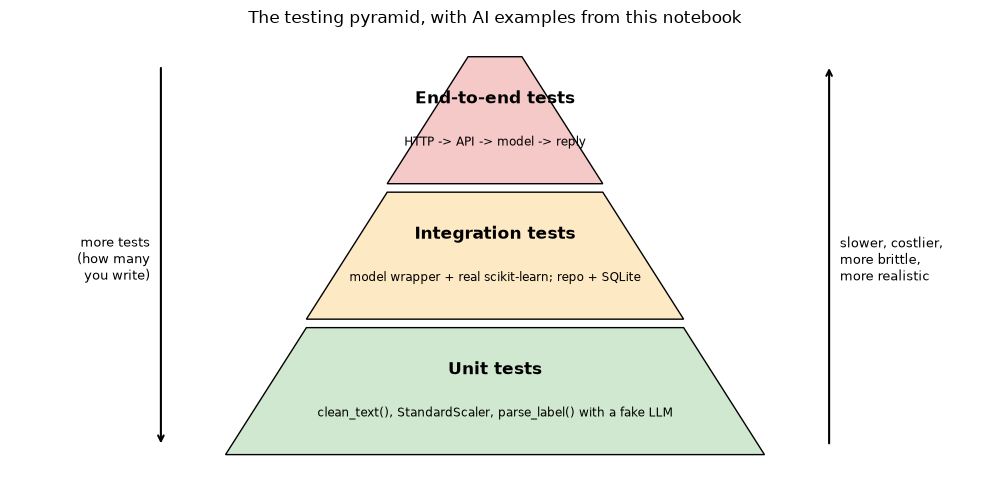

In [2]:
fig, ax = plt.subplots(figsize=(10, 5))
levels = [  # (label, AI example, width at bottom, width at top, colour)
    ("Unit tests", "clean_text(), StandardScaler, parse_label() with a fake LLM", 10, 7, "#cfe8cf"),
    ("Integration tests", "model wrapper + real scikit-learn; repo + SQLite", 7, 4, "#fde9c4"),
    ("End-to-end tests", "HTTP -> API -> model -> reply", 4, 1, "#f6c9c9"),
]
for i, (name, example, wb, wt, colour) in enumerate(levels):
    y0, y1 = i * 1.6, i * 1.6 + 1.5
    ax.fill([5 - wb / 2, 5 + wb / 2, 5 + wt / 2, 5 - wt / 2], [y0, y0, y1, y1], color=colour, ec="black")
    ax.text(5, y0 + 0.95, name, ha="center", fontsize=12, fontweight="bold")
    ax.text(5, y0 + 0.45, example, ha="center", fontsize=8.5)
ax.annotate("", xy=(11.2, 4.6), xytext=(11.2, 0.1), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.text(11.4, 2.3, "slower, costlier,\nmore brittle,\nmore realistic", va="center", fontsize=9)
ax.annotate("", xy=(-1.2, 0.1), xytext=(-1.2, 4.6), arrowprops=dict(arrowstyle="->", lw=1.5))
ax.text(-1.4, 2.3, "more tests\n(how many\nyou write)", va="center", ha="right", fontsize=9)
ax.set_xlim(-4, 14); ax.set_ylim(-0.3, 5); ax.axis("off")
ax.set_title("The testing pyramid, with AI examples from this notebook")
plt.tight_layout(); plt.show()

| | Unit | Integration | End-to-end |
|---|---|---|---|
| Scope | one function/class | a few real components together | the whole deployed system |
| External services | none (fakes/mocks) | some real (SQLite, scikit-learn, local files) | all real (or staging copies) |
| Speed | ms | 100 ms to seconds | seconds to minutes |
| When it fails, you know... | exactly which function | which interaction | only *that* something is wrong |
| AI examples here | `clean_text`, `StandardScaler`, `parse_label` | training `SentimentModel` on generated data | (in [12_FastAPI/04](../12_FastAPI/04_industry_production_ml_api.ipynb): POST `/predict` through a real app) |
| Run | on every save/commit | on every push / pull request | before release, nightly |

ML adds two more kinds that don't fit the classic pyramid neatly: **data tests** (is the input what we expect?) and **model-quality tests** (is the model still good enough?). The *ML Test Score* rubric by Breck et al. (Google, 2017) lists 28 such tests across data, model, infrastructure and monitoring. Section 7 implements the most important ones.

> ⚠️ **Common mistake: the "ice-cream cone".** Teams that test only by clicking through the app or eyeballing notebook outputs have the pyramid upside down: slow, flaky feedback and bugs found late.

---
## 2. The project under test: a small `aikit` package

> 💡 **In plain English:** we build a small but realistic AI package on disk, so we can test it the way real teams do.

To test like in a real job, we need real files. We write a small package into a temporary folder:

```
<project>/
├── pytest.ini                 pytest configuration
├── aikit/
│   ├── __init__.py
│   ├── text.py                clean_text(), tokenize()          (pure functions)
│   ├── features.py            StandardScaler                    (a feature transformer)
│   ├── data.py                make_reviews()                    (synthetic labelled data)
│   ├── model.py               SentimentModel                    (a model wrapper)
│   ├── llm.py                 LLMTicketClassifier + HTTPLLMClient (LLM-backed, injectable client)
│   └── validation.py          validate_tickets()                (data validation)
└── tests/
    ├── conftest.py            shared fixtures and options
    └── test_*.py              one test file per module
```

Notice the design: `LLMTicketClassifier` receives its client in `__init__` (dependency injection, notebook 01, §9.5), and `SentimentModel` owns its preprocessing (no training/serving skew). Those choices are what make the code testable.

In [3]:
write("aikit/__init__.py", r"""
"aikit: a tiny AI toolkit used to practise testing."
__version__ = "0.1.0"
""")

write("aikit/text.py", r"""
"Text cleaning shared by training and serving."
import re
import unicodedata

URL_RE = re.compile(r"https?://\S+")
_PUNCT_RE = re.compile(r"[^\w\s<>']")          # keep word characters, spaces, the <url> tag, apostrophes


def clean_text(text: str) -> str:
    "Normalise unicode, replace URLs, lowercase, drop punctuation, collapse whitespace."
    if not isinstance(text, str):
        raise TypeError(f"expected str, got {type(text).__name__}")
    text = unicodedata.normalize("NFKC", text)  # e.g. full-width letters -> ASCII
    text = URL_RE.sub(" <url> ", text)
    text = text.lower()
    text = _PUNCT_RE.sub(" ", text)
    return " ".join(text.split())


def tokenize(text: str) -> list[str]:
    return clean_text(text).split()
""")

write("aikit/features.py", r"""
"A small standard scaler for numeric features (mean 0, standard deviation 1)."
import json

import numpy as np


class NotFittedError(RuntimeError):
    "Raised when transform() is called before fit()."


class StandardScaler:
    def __init__(self):
        self.mean_ = None
        self.scale_ = None

    def fit(self, X):
        X = self._check_2d(X)
        self.mean_ = X.mean(axis=0)
        scale = X.std(axis=0)
        scale[scale == 0.0] = 1.0                 # constant column: avoid dividing by zero
        self.scale_ = scale
        return self

    def transform(self, X):
        if self.mean_ is None:
            raise NotFittedError("call fit() before transform()")
        X = self._check_2d(X)
        if X.shape[1] != self.mean_.shape[0]:
            raise ValueError(f"expected {self.mean_.shape[0]} features, got {X.shape[1]}")
        return (X - self.mean_) / self.scale_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

    def inverse_transform(self, Z):
        return np.asarray(Z, dtype=float) * self.scale_ + self.mean_

    def save(self, path):
        with open(path, "w") as f:
            json.dump({"mean": self.mean_.tolist(), "scale": self.scale_.tolist()}, f)

    @classmethod
    def load(cls, path):
        with open(path) as f:
            d = json.load(f)
        obj = cls()
        obj.mean_, obj.scale_ = np.array(d["mean"]), np.array(d["scale"])
        return obj

    @staticmethod
    def _check_2d(X):
        X = np.asarray(X, dtype=float)
        if X.ndim != 2:
            raise ValueError(f"expected a 2-D array, got {X.ndim}-D")
        if not np.isfinite(X).all():
            raise ValueError("X contains NaN or infinity")
        return X
""")

write("aikit/data.py", r"""
"Synthetic movie reviews from templates (deterministic for a given seed)."
import random

POS = ["great", "wonderful", "excellent", "enjoyable", "brilliant", "good", "fantastic", "superb"]
NEG = ["awful", "terrible", "boring", "bad", "dull", "poor", "dreadful", "weak"]
SUBJECTS = ["the movie", "the film", "the plot", "the acting", "the soundtrack", "the ending", "this show"]
NAMES = ["Ali", "Maria", "John", "Aisha", "Chen", "Fatima", "Lucas", "Sara"]
CITIES = ["Paris", "Lahore", "Tokyo", "Lagos", "Berlin", "Lima", "Dubai", "Oslo"]
TEMPLATES = [
    "{subject} was {adj}",
    "{name} said {subject} was {adj}",
    "I watched it in {city} and {subject} was {adj}",
    "honestly {subject} was {adj} and {adj2}",
]


def make_reviews(n, seed=0):
    rng = random.Random(seed)
    texts, labels = [], []
    for i in range(n):
        label = "pos" if i % 2 == 0 else "neg"      # perfectly balanced classes
        words = POS if label == "pos" else NEG
        template = rng.choice(TEMPLATES)
        texts.append(template.format(subject=rng.choice(SUBJECTS), adj=rng.choice(words),
                                     adj2=rng.choice(words), name=rng.choice(NAMES),
                                     city=rng.choice(CITIES)))
        labels.append(label)
    return texts, labels
""")

write("aikit/model.py", r"""
"Sentiment model wrapper: one object owns preprocessing and model, so training and serving can't drift."
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.pipeline import make_pipeline

from aikit.text import clean_text


class SentimentModel:
    def __init__(self, seed=0, epochs=30):
        self.seed, self.epochs = seed, epochs
        self.pipeline = None

    def fit(self, texts, labels):
        self.pipeline = make_pipeline(
            CountVectorizer(preprocessor=clean_text),
            # SGD shuffles the data each epoch, so the seed matters; tol=None runs all epochs
            SGDClassifier(loss="log_loss", alpha=1e-3, max_iter=self.epochs, tol=None,
                          random_state=self.seed),
        )
        self.pipeline.fit(list(texts), list(labels))
        return self

    def predict_proba(self, texts):
        "P(label == 'pos') for each text."
        if self.pipeline is None:
            raise RuntimeError("model is not trained")
        pos_column = list(self.pipeline[-1].classes_).index("pos")
        return self.pipeline.predict_proba(list(texts))[:, pos_column]

    def predict(self, texts):
        return ["pos" if p >= 0.5 else "neg" for p in self.predict_proba(texts)]

    @property
    def coef_(self):
        return self.pipeline[-1].coef_.copy()
""")

write("aikit/llm.py", r"""
"An LLM-backed support-ticket classifier with an injectable client."
from typing import Protocol

import httpx

LABELS = ("billing", "tech", "other")
PROMPT_TEMPLATE = (
    "You are a support-ticket router.\n"
    "Classify the ticket into exactly one of: billing, tech, other.\n"
    "Answer with the label only.\n\n"
    "Ticket: {ticket}\n"
    "Label:"
)
MAX_TICKET_CHARS = 500


class LLMError(Exception):
    "Any failure while talking to the LLM provider."


class LLMClient(Protocol):
    def complete(self, prompt: str) -> str: ...


def build_prompt(ticket: str) -> str:
    ticket = " ".join(ticket.split())[:MAX_TICKET_CHARS]
    return PROMPT_TEMPLATE.format(ticket=ticket)


def parse_label(raw: str) -> str:
    "Map a free-form LLM reply to one of LABELS; anything unexpected becomes 'other'."
    words = raw.strip().lower().replace(".", " ").replace(":", " ").split()
    return words[0] if words and words[0] in LABELS else "other"


class LLMTicketClassifier:
    def __init__(self, client: LLMClient, max_retries: int = 2):
        self.client, self.max_retries = client, max_retries

    def classify(self, ticket: str) -> str:
        prompt = build_prompt(ticket)
        for attempt in range(self.max_retries + 1):
            try:
                return parse_label(self.client.complete(prompt))
            except LLMError:
                if attempt == self.max_retries:
                    raise


class HTTPLLMClient:
    "Calls a (hypothetical) JSON completion endpoint over HTTP."

    def __init__(self, url: str, api_key: str, timeout: float = 10.0):
        self.url, self.api_key, self.timeout = url, api_key, timeout

    def complete(self, prompt: str) -> str:
        try:
            r = httpx.post(self.url, json={"prompt": prompt, "temperature": 0},
                           headers={"Authorization": f"Bearer {self.api_key}"}, timeout=self.timeout)
        except httpx.TimeoutException as e:
            raise LLMError("timeout") from e
        if r.status_code != 200:
            raise LLMError(f"HTTP {r.status_code}")
        return r.json()["text"]
""")

write("aikit/validation.py", r"""
"Validation for the labelled-tickets table: a lightweight data contract."
import pandas as pd
from pandas.api.types import is_float_dtype, is_integer_dtype, is_string_dtype

from aikit.llm import LABELS

SCHEMA = {  # column -> (dtype check, human-readable kind)
    "ticket_id": (is_integer_dtype, "an integer"),
    "text": (is_string_dtype, "a string"),
    "label": (is_string_dtype, "a string"),
    "confidence": (is_float_dtype, "a float"),
}


def validate_tickets(df: pd.DataFrame) -> list[str]:
    "Return a list of human-readable problems; an empty list means the data is valid."
    missing = [c for c in SCHEMA if c not in df.columns]
    if missing:
        return [f"missing columns: {missing}"]       # nothing else can be checked reliably
    errors = []
    for col, (check, kind) in SCHEMA.items():
        if not check(df[col].dropna()):              # nulls are reported separately below
            errors.append(f"{col}: expected {kind} dtype, got {df[col].dtype}")
    for col in ("text", "label"):
        n_null = int(df[col].isna().sum())
        if n_null:
            errors.append(f"{col}: {n_null} null value(s)")
    if df["ticket_id"].duplicated().any():
        errors.append("ticket_id: duplicates found")
    out_of_range = int(((df["confidence"] < 0) | (df["confidence"] > 1)).sum())
    if out_of_range:
        errors.append(f"confidence: {out_of_range} value(s) outside [0, 1]")
    unknown = set(df["label"].dropna()) - set(LABELS)
    if unknown:
        errors.append(f"label: unknown values {sorted(unknown)}")
    n_empty = int(df["text"].dropna().str.strip().eq("").sum())
    if n_empty:
        errors.append(f"text: {n_empty} empty string(s)")
    return errors
""")

write("pytest.ini", r"""
[pytest]
# make `import aikit` work from the tests without installing the package
pythonpath = .
testpaths = tests
# don't write a .pytest_cache folder
addopts = -p no:cacheprovider
markers =
    slow: trains a model or does heavy work (deselect with -m "not slow")
""")

wrote aikit/__init__.py                    2 lines
wrote aikit/text.py                       21 lines
wrote aikit/features.py                   57 lines
wrote aikit/data.py                       28 lines
wrote aikit/model.py                      36 lines
wrote aikit/llm.py                        64 lines
wrote aikit/validation.py                 39 lines
wrote pytest.ini                           8 lines


In [4]:
# A quick smoke check from the notebook itself: import the package we just wrote.
sys.path.insert(0, str(WORK))
import aikit.text, aikit.features, aikit.model, aikit.llm, aikit.data
print(aikit.text.clean_text("Check https://example.com/docs — it's GREAT!!"))
texts, labels = aikit.data.make_reviews(6, seed=0)
for t, l in zip(texts, labels):
    print(f"  {l}: {t}")

check <url> it's great
  pos: honestly this show was fantastic and great
  neg: honestly this show was dull and weak
  pos: Chen said the plot was excellent
  neg: I watched it in Lahore and the movie was terrible
  pos: I watched it in Oslo and the acting was good
  neg: I watched it in Paris and the movie was awful


---
## 3. Your first pytest run, and reading a failure

> 💡 **In plain English:** pytest finds your test functions, runs them, and tells you exactly what broke and where.

**pytest** finds tests automatically: files named `test_*.py`, functions named `test_*`, classes named `Test*`. Inside a test you use the plain `assert` statement; pytest rewrites it so that a failure shows the values involved.

Our first test file uses **`parametrize`** to run one test function over a table of examples (section 4 explains it in detail). The `ids` give each case a readable name.

In [5]:
write("tests/test_text.py", r"""
import pytest

from aikit.text import clean_text, tokenize


@pytest.mark.parametrize(
    "raw, expected",
    [
        ("Hello, World!", "hello world"),
        ("  lots   of\tspace\n", "lots of space"),
        ("Don't panic!", "don't panic"),
        ("see https://example.com/docs now", "see <url> now"),
        ("Ｆｕｌｌ", "full"),          # full-width letters, normalised by NFKC
        ("", ""),
    ],
    ids=["punctuation", "whitespace", "apostrophe", "url", "fullwidth", "empty"],
)
def test_clean_text_examples(raw, expected):
    assert clean_text(raw) == expected


def test_tokenize_splits_clean_text():
    assert tokenize("GPU's are FAST!!") == ["gpu's", "are", "fast"]


def test_clean_text_rejects_non_strings():
    with pytest.raises(TypeError, match="expected str"):
        clean_text(None)
""")
pytest("tests/test_text.py", "-v")

wrote tests/test_text.py                  28 lines


============================= test session starts ==============================
platform linux -- Python 3.12.3, pytest-9.1.1, pluggy-1.7.0 -- <venv>/bin/python
rootdir: <project>
configfile: pytest.ini
collecting ... collected 8 items

tests/test_text.py::test_clean_text_examples[punctuation] PASSED         [ 12%]
tests/test_text.py::test_clean_text_examples[whitespace] PASSED          [ 25%]
tests/test_text.py::test_clean_text_examples[apostrophe] PASSED          [ 37%]
tests/test_text.py::test_clean_text_examples[url] PASSED                 [ 50%]
tests/test_text.py::test_clean_text_examples[fullwidth] PASSED           [ 62%]
tests/test_text.py::test_clean_text_examples[empty] PASSED               [ 75%]
tests/test_text.py::test_tokenize_splits_clean_text PASSED               [ 87%]
tests/test_text.py::test_clean_text_rejects_non_strings PASSED           [100%]

============================== 8 passed in 0.03s ===============================
[exit code 0]


**What just happened?** pytest collected 8 tests (6 parametrized cases + 2 functions) and all passed. With `-v` (verbose) each test is listed with its **node id**: `file::function[case-id]`. You can run a single case with exactly that id, e.g. `pytest "tests/test_text.py::test_clean_text_examples[url]"`. The exit code is **0**: CI systems only look at this number.

### A deliberate bug

A teammate "simplifies" the punctuation rule and accidentally drops the apostrophe from the allowed characters. Let's see how the tests react, and learn to read the report.

In [6]:
text_py = WORK / "aikit/text.py"
original_text_py = text_py.read_text()
text_py.write_text(original_text_py.replace(r"[^\w\s<>']", r"[^\w\s<>]"))   # the "harmless" edit
pytest("tests/test_text.py", "-q", "--tb=short")

..F...F.                                                                 [100%]
=================================== FAILURES ===================================
_____________________ test_clean_text_examples[apostrophe] _____________________
tests/test_text.py:19: in test_clean_text_examples
    assert clean_text(raw) == expected
E   assert 'don t panic' == "don't panic"
E     
E     - don't panic
E     ?    ^
E     + don t panic
E     ?    ^
_______________________ test_tokenize_splits_clean_text ________________________
tests/test_text.py:23: in test_tokenize_splits_clean_text
    assert tokenize("GPU's are FAST!!") == ["gpu's", "are", "fast"]
E   assert ['gpu', 's', 'are', 'fast'] == ["gpu's", 'are', 'fast']
E     
E     At index 0 diff: 'gpu' != "gpu's"
E     Left contains one more item: 'fast'
E     Use -v to get more diff
=========================== short test summary info ============================
FAILED tests/test_text.py::test_clean_text_examples[apostrophe] - assert 'don..

**How to read a pytest failure, top to bottom:**

1. **The progress line** (`..F...F.`): one character per test: `.` passed, `F` failed, `E` error (crash in a fixture or setup), `s` skipped, `x` expected failure, `X` unexpectedly passed.
2. **The FAILURES section**, one block per failing test, headed by its node id (`test_clean_text_examples[apostrophe]`). That id tells you *which input* broke, without a debugger.
3. **The `assert` line and the `E` lines**: pytest shows the evaluated values. Here `'don t panic' == "don't panic"`, so the apostrophe was turned into a space.
4. **`file:line`** of the failing assertion (`tests/test_text.py:19`), to jump straight there.
5. **The short test summary** at the bottom (`FAILED ...`) and the count: **2 failed, 6 passed**, exit code **1**.

Both failures point to the same cause: apostrophes. Two tests failing for one reason is common; always fix the root cause, not each symptom. We restore the original rule:

In [7]:
text_py.write_text(original_text_py)                       # revert the bug
pytest("tests/test_text.py", "-q")
assert LAST_EXIT_CODE[0] == 0

........                                                                 [100%]
8 passed in 0.02s
[exit code 0]


---
## 4. pytest features: fixtures, parametrize, marks, raises, approx

> 💡 **In plain English:** tools that make tests shorter: shared setup (fixtures), tables of cases, labels, and float-friendly comparisons.

### 4.1 Fixtures

A **fixture** is a function that prepares something a test needs (data, a fitted object, a temporary folder, a fake client) and optionally cleans it up afterwards. A test **requests** a fixture simply by naming it as a parameter; pytest calls the fixture and passes in the result. This is dependency injection for tests.

| Scope | Created | Use for |
|---|---|---|
| `function` (default) | once per test | anything mutable: each test gets a fresh copy |
| `class` | once per test class | shared setup for a group of related tests |
| `module` | once per test file | expensive, read-only objects used by one file |
| `package` | once per test package (folder) | rarely needed |
| `session` | once per whole pytest run | very expensive, read-only objects: a trained model, a loaded dataset |

Code after a `yield` inside a fixture is **teardown**: it runs after the tests that used it, even if they failed. Built-in fixtures include **`tmp_path`** (a fresh temporary directory per test, as a `pathlib.Path`), `monkeypatch` (set env vars or attributes for one test), and `capsys` (capture printed output).

`--setup-show` makes pytest print when each fixture is set up and torn down, with its scope letter (S, M, F):

In [8]:
write("tests/test_fixture_demo.py", r"""
import pytest


@pytest.fixture(scope="module")
def expensive_model():
    model = {"name": "tiny-model", "loaded": True}   # imagine loading 2 GB of weights here
    yield model                                      # tests run while we are paused here
    model["loaded"] = False                          # teardown: free memory, close files


@pytest.fixture
def request_payload():                               # function scope: a fresh dict per test
    return {"text": "hello"}


def test_one(expensive_model, request_payload):
    request_payload["text"] = "changed"              # mutating it can't affect other tests
    assert expensive_model["loaded"]


def test_two(expensive_model, request_payload, tmp_path):
    assert request_payload["text"] == "hello"        # fresh again
    (tmp_path / "out.txt").write_text("ok")          # tmp_path: a new empty folder for this test
    assert (tmp_path / "out.txt").read_text() == "ok"
""")
pytest("tests/test_fixture_demo.py", "--setup-show", "-q")

wrote tests/test_fixture_demo.py          24 lines



    SETUP    M expensive_model
        SETUP    F request_payload
        tests/test_fixture_demo.py::test_one (fixtures used: expensive_model, request_payload) .
        TEARDOWN F request_payload
SETUP    S tmp_path_factory
        SETUP    F request_payload
        SETUP    F tmp_path (fixtures used: tmp_path_factory)
        tests/test_fixture_demo.py::test_two (fixtures used: expensive_model, request, request_payload, tmp_path, tmp_path_factory) .
        TEARDOWN F tmp_path
        TEARDOWN F request_payload
    TEARDOWN M expensive_model
TEARDOWN S tmp_path_factory
2 passed in 0.02s
[exit code 0]


**What just happened?** `expensive_model` (scope **M**odule) was set up **once** and shared by both tests, then torn down at the end of the file. `request_payload` (scope **F**unction) was created for each test, so `test_one`'s mutation did not leak into `test_two`. `tmp_path` is built on the session-scoped `tmp_path_factory` (scope **S**).

> ⚠️ **Common mistake:** giving a *mutable* object a wide scope (`session`) and letting tests modify it. Tests then pass or fail depending on their order, exactly the singleton problem from notebook 02. Wide scopes only for read-only things.

### 4.2 `conftest.py`: shared fixtures and options

Fixtures defined in `tests/conftest.py` are available to every test in that folder without importing anything. It is also where you add **command-line options** (with the `pytest_addoption` hook). Ours provides a session-scoped dataset and trained model (training once for the whole run instead of once per test), and a `--update-golden` option used in section 7.4.

In [9]:
write("tests/conftest.py", r"""
import pytest

from aikit.data import make_reviews


def pytest_addoption(parser):
    parser.addoption("--update-golden", action="store_true", default=False,
                     help="rewrite golden files instead of comparing against them")


@pytest.fixture
def update_golden(request):
    return request.config.getoption("--update-golden")


@pytest.fixture(scope="session")
def reviews():
    return make_reviews(n=400, seed=0)                 # built once per test run


@pytest.fixture(scope="session")
def trained_model(reviews):                            # fixtures can use other fixtures
    from aikit.model import SentimentModel             # imported lazily: scikit-learn is slow to import
    texts, labels = reviews
    return SentimentModel(seed=0).fit(texts, labels)
""")

wrote tests/conftest.py                   25 lines


### 4.3 `raises`, `approx`, `parametrize` on a feature transformer

- **`pytest.raises(ErrorType, match=regex)`** asserts that a block raises that error, with a message matching the regex. Testing the *unhappy* paths (bad input, wrong order of calls) is where many real bugs hide.
- **`pytest.approx`** compares floats with a tolerance. Floating-point arithmetic is not exact (`0.1 + 0.2 != 0.3`), so `==` on floats is almost always wrong. Default tolerance: relative `1e-6` (and absolute `1e-12`). For numpy arrays, `np.testing.assert_allclose` gives better failure messages.
- **`parametrize`** with `ids` runs one test over a table of inputs, each reported separately.

In [10]:
write("tests/test_features.py", r"""
import numpy as np
import pytest

from aikit.features import NotFittedError, StandardScaler


@pytest.fixture
def X():
    # 3 rows, 3 features; the last column is constant on purpose
    return np.array([[1.0, 10.0, 5.0], [2.0, 20.0, 5.0], [3.0, 30.0, 5.0]])


def test_fit_learns_mean_and_std(X):
    s = StandardScaler().fit(X)
    assert s.mean_ == pytest.approx([2.0, 20.0, 5.0])
    assert s.scale_ == pytest.approx([np.sqrt(2 / 3), 10 * np.sqrt(2 / 3), 1.0])


def test_transform_gives_zero_mean_unit_std(X):
    Z = StandardScaler().fit(X).transform(X)
    np.testing.assert_allclose(Z[:, :2].mean(axis=0), 0.0, atol=1e-12)
    np.testing.assert_allclose(Z[:, :2].std(axis=0), 1.0, rtol=1e-12)


def test_constant_column_does_not_produce_nan(X):
    Z = StandardScaler().fit(X).transform(X)
    assert not np.isnan(Z).any()
    assert (Z[:, 2] == 0).all()


def test_inverse_transform_round_trips(X):
    s = StandardScaler().fit(X)
    np.testing.assert_allclose(s.inverse_transform(s.transform(X)), X)


def test_transform_before_fit_raises():
    with pytest.raises(NotFittedError, match="fit"):
        StandardScaler().transform([[1.0]])


@pytest.mark.parametrize("bad", [[1.0, 2.0], [[1.0, np.nan]], [[np.inf, 1.0]]], ids=["1-D", "nan", "inf"])
def test_rejects_bad_input(bad):
    with pytest.raises(ValueError):
        StandardScaler().fit(bad)


def test_wrong_number_of_features_raises(X):
    s = StandardScaler().fit(X)
    with pytest.raises(ValueError, match="expected 3 features, got 2"):
        s.transform([[1.0, 2.0]])


def test_save_and_load(tmp_path, X):
    path = tmp_path / "scaler.json"
    StandardScaler().fit(X).save(path)
    loaded = StandardScaler.load(path)
    np.testing.assert_allclose(loaded.transform(X), StandardScaler().fit(X).transform(X))
""")
pytest("tests/test_features.py", "-v")

wrote tests/test_features.py              57 lines


============================= test session starts ==============================
platform linux -- Python 3.12.3, pytest-9.1.1, pluggy-1.7.0 -- <venv>/bin/python
rootdir: <project>
configfile: pytest.ini
collecting ... collected 10 items

tests/test_features.py::test_fit_learns_mean_and_std PASSED              [ 10%]
tests/test_features.py::test_transform_gives_zero_mean_unit_std PASSED   [ 20%]
tests/test_features.py::test_constant_column_does_not_produce_nan PASSED [ 30%]
tests/test_features.py::test_inverse_transform_round_trips PASSED        [ 40%]
tests/test_features.py::test_transform_before_fit_raises PASSED          [ 50%]
tests/test_features.py::test_rejects_bad_input[1-D] PASSED               [ 60%]
tests/test_features.py::test_rejects_bad_input[nan] PASSED               [ 70%]
tests/test_features.py::test_rejects_bad_input[inf] PASSED               [ 80%]
tests/test_features.py::test_wrong_number_of_features_raises PASSED      [ 90%]
tests/test_features.py::test_save_and_loa

**What just happened?** 10 tests passed: the happy path (correct mean and standard deviation, zero mean and unit variance after transforming), an **edge case** (a constant column must not produce NaN through division by zero), a **round trip** (inverse of transform gives the input back), four **unhappy paths** (transform before fit; 1-D, NaN and infinite input) and a **persistence** test that writes into a fresh `tmp_path`.

### 4.4 Marks: `skip`, `skipif`, `xfail` and custom marks

| Mark | Meaning | Example |
|---|---|---|
| `@pytest.mark.skip(reason=...)` | don't run it | a test for a feature not built yet |
| `@pytest.mark.skipif(cond, reason=...)` | skip when a condition holds | `sys.platform == "win32"`, "no GPU" |
| `pytest.importorskip("lib")` | skip the module if an optional library is missing | the hypothesis tests in section 6 |
| `@pytest.mark.xfail(reason=..., strict=True)` | expected to fail; with `strict=True`, an unexpected *pass* is reported as a failure | a known model limitation (section 7.3) |
| custom, e.g. `@pytest.mark.slow` | a label you can select on: `-m "not slow"` | model training tests |

Custom marks must be **registered** (we did, in `pytest.ini`), otherwise pytest warns about typos like `@pytest.mark.slwo`. The `-rsx` flag prints the reasons for skips and xfails in the summary.

In [11]:
write("tests/test_marks_demo.py", r"""
import sys

import pytest


@pytest.mark.skipif(sys.version_info < (3, 99), reason="needs Python 3.99 (a future version)")
def test_future_feature():
    assert False                      # never runs on today's Python


@pytest.mark.skipif(not sys.platform.startswith("linux"), reason="Linux-only path handling")
def test_linux_only():
    assert "/" in "/tmp"


@pytest.mark.xfail(reason="documented bug #123: emoji are dropped", strict=True)
def test_emoji_kept():
    from aikit.text import clean_text
    assert clean_text("great 👍") == "great 👍"
""")
pytest("tests/test_marks_demo.py", "-q", "-rsx")

wrote tests/test_marks_demo.py            19 lines


s.x                                                                      [100%]
=========================== short test summary info ============================
SKIPPED [1] tests/test_marks_demo.py:6: needs Python 3.99 (a future version)
XFAIL tests/test_marks_demo.py::test_emoji_kept - documented bug #123: emoji are dropped
1 passed, 1 skipped, 1 xfailed in 0.03s
[exit code 0]


**What just happened?** One test passed (we run on Linux), one was **skipped** with its reason, and one **xfailed**: `clean_text` drops emoji because they are neither word characters nor spaces. The xfail documents a known limitation *in the test suite*; with `strict=True`, the day someone fixes it, the test will "unexpectedly pass" and fail the run, reminding them to remove the mark.

---
## 5. Mocking LLM and HTTP calls (and dependency injection instead)

> 💡 **In plain English:** replace slow, paid or unreliable services with pretend ones while testing.

Unit tests must not call real LLM APIs: that is slow, costs money, needs secrets in CI, and is **non-deterministic**. Two ways to replace the real thing:

1. **Dependency injection (preferred when you own the code):** pass a hand-written **fake** object (`FakeLLM`) into the constructor. No magic, and it works because the class was designed for it.
2. **Mocking:** `unittest.mock` (standard library) creates stand-in objects and can temporarily **patch** a name inside a module, for code you can't (or don't want to) restructure, such as a module-level `httpx.post` call.

A few words of vocabulary (Gerard Meszaros, *xUnit Test Patterns*, 2007): a **stub** returns canned answers; a **fake** is a working lightweight implementation (an in-memory repository); a **mock** also *records calls* so you can assert how it was used. `MagicMock` can play all three roles.

In [12]:
# MagicMock basics, in the notebook.
llm = MagicMock()
llm.complete.return_value = "Billing."                     # stub: canned answer
print("reply        :", llm.complete("anything"))
print("called with  :", llm.complete.call_args, "| count:", llm.complete.call_count)
llm.complete.assert_called_once_with("anything")           # mock: verify the interaction

llm.complete.side_effect = [aikit.llm.LLMError("503"), "tech"]   # a list: one result per call
for _ in range(2):
    try:
        print("side_effect  :", llm.complete("x"))
    except aikit.llm.LLMError as e:
        print("side_effect  : raised LLMError", e)

loose = MagicMock()
print("typo on a plain MagicMock silently works:", type(loose.compelte("x")).__name__)
strict = MagicMock(spec=aikit.llm.HTTPLLMClient)           # spec: only real attributes allowed
try:
    strict.compelte("x")
except AttributeError as e:
    print("with spec=   :", e)

reply        : Billing.
called with  : call('anything') | count: 1
side_effect  : raised LLMError 503
side_effect  : tech
typo on a plain MagicMock silently works: MagicMock
with spec=   : Mock object has no attribute 'compelte'


**What just happened?** `return_value` scripted a reply; `call_args`/`assert_called_once_with` checked how we were called; `side_effect` with a list returned a different outcome per call, including raising an exception (perfect for testing retries). A plain `MagicMock` happily accepts a typo (`compelte`) and returns another mock, so the test passes while testing nothing. **`spec=`** (or `create_autospec`, which also checks argument signatures) makes the mock reject attributes the real class doesn't have.

### Patch where it is *looked up*, not where it is defined

`patch("module.name")` replaces `name` **inside `module`** while the test runs. The classic trap: if `aikit/clock.py` does `from time import time`, it has its *own* name `time`, so patching `time.time` doesn't affect it.

In [13]:
write("aikit/clock.py", r"""
from time import time            # copies the function into this module's namespace


def timestamp_ms():
    return int(time() * 1000)
""")
import aikit.clock

with patch("time.time", return_value=1.0):                  # patches the time module...
    print("patch('time.time')        ->", aikit.clock.timestamp_ms() == 1000, "(still the real clock)")
with patch("aikit.clock.time", return_value=1.0):           # ...but aikit.clock looks up ITS OWN name
    print("patch('aikit.clock.time') ->", aikit.clock.timestamp_ms() == 1000)

wrote aikit/clock.py                       5 lines
patch('time.time')        -> False (still the real clock)
patch('aikit.clock.time') -> True


Our `aikit/llm.py` does `import httpx` and calls `httpx.post(...)`, so we patch `aikit.llm.httpx.post`. Now the test file for the LLM module, using **both** techniques:

In [14]:
write("tests/test_llm.py", r"""
from unittest.mock import MagicMock, patch

import httpx
import pytest

from aikit.llm import HTTPLLMClient, LLMError, LLMTicketClassifier, build_prompt, parse_label


@pytest.mark.parametrize("raw, label", [
    ("billing", "billing"), ("  Tech.\n", "tech"), ("OTHER: not sure", "other"),
    ("I think billing", "other"), ("", "other"),
])
def test_parse_label(raw, label):
    assert parse_label(raw) == label


def test_prompt_contains_ticket_and_labels():
    p = build_prompt("  My   invoice is wrong ")
    assert "Ticket: My invoice is wrong" in p
    assert "billing, tech, other" in p


def test_prompt_truncates_long_tickets():
    assert len(build_prompt("x" * 10_000)) < 700


# ---- 1) dependency injection: a hand-written fake, no mocking library needed ----
class FakeLLM:
    def __init__(self, reply):
        self.reply, self.prompts = reply, []

    def complete(self, prompt):
        self.prompts.append(prompt)
        return self.reply


def test_classifier_with_fake():
    fake = FakeLLM("Billing.")
    assert LLMTicketClassifier(fake).classify("refund please") == "billing"
    assert "refund please" in fake.prompts[0]


# ---- 2) MagicMock: scripted behaviour plus call assertions ----
def test_classifier_retries_then_succeeds():
    client = MagicMock()
    client.complete.side_effect = [LLMError("503"), "tech"]
    assert LLMTicketClassifier(client, max_retries=2).classify("app crashes") == "tech"
    assert client.complete.call_count == 2


def test_classifier_gives_up_after_retries():
    client = MagicMock()
    client.complete.side_effect = LLMError("down")
    with pytest.raises(LLMError):
        LLMTicketClassifier(client, max_retries=2).classify("hello")
    assert client.complete.call_count == 3          # 1 try + 2 retries


# ---- 3) patch: replace httpx.post where aikit.llm looks it up ----
@patch("aikit.llm.httpx.post")
def test_http_client_sends_prompt(mock_post):
    mock_post.return_value = MagicMock(status_code=200, json=lambda: {"text": "billing"})
    client = HTTPLLMClient("https://llm.example.com/v1/complete", api_key="test-key")
    assert client.complete("hi") == "billing"
    mock_post.assert_called_once()
    _, kwargs = mock_post.call_args
    assert kwargs["json"] == {"prompt": "hi", "temperature": 0}
    assert kwargs["headers"]["Authorization"] == "Bearer test-key"


@patch("aikit.llm.httpx.post", side_effect=httpx.TimeoutException("too slow"))
def test_http_timeout_becomes_llm_error(mock_post):
    with pytest.raises(LLMError, match="timeout"):
        HTTPLLMClient("https://llm.example.com", api_key="k").complete("hi")


@patch("aikit.llm.httpx.post")
def test_http_error_status_becomes_llm_error(mock_post):
    mock_post.return_value = MagicMock(status_code=429)
    with pytest.raises(LLMError, match="HTTP 429"):
        HTTPLLMClient("https://llm.example.com", api_key="k").complete("hi")
""")
pytest("tests/test_llm.py", "-q")

wrote tests/test_llm.py                   81 lines


.............                                                            [100%]
13 passed in 0.26s
[exit code 0]


**What just happened?** 13 tests passed in well under a second, with no network, no API key and no cost. We checked label parsing on messy replies ("  Tech.\n"), the prompt contents, retries (fail once, then succeed; or give up after 3 calls), the exact HTTP request our client sends, and how timeouts and HTTP 429 are translated into our own `LLMError`.

| | Fake via dependency injection | `MagicMock` / `patch` |
|---|---|---|
| Needs code designed for it? | yes (client passed in) | no |
| Readability | plain Python, explicit | can get magical (`side_effect`, patch targets) |
| Risk | the fake drifts from the real API | over-mocking: tests pass while real integration breaks; patching the wrong name |
| Best for | your own classes and services | third-party calls (`httpx.post`), time, randomness, legacy code |

> ⚠️ **Common mistake: mocking everything.** If a test mocks every collaborator, it only checks that your code calls mocks in a certain order, and breaks on every refactor. Mock at the **boundaries** (network, clock, randomness, paid APIs) and use real objects inside. Add a few **integration tests** against the real thing (a local model, a staging endpoint) that run less often.

---
## 6. Property-based testing

> 💡 **In plain English:** instead of a few hand-picked examples, check a rule that must hold for hundreds of generated inputs.

Example-based tests check the inputs **you** thought of. **Property-based testing** (introduced by QuickCheck for Haskell, Claessen and Hughes, 2000) checks a **property** that must hold for *all* inputs, against hundreds of **generated** inputs, including nasty ones you'd never write by hand (empty strings, Unicode oddities, huge numbers).

Good properties for AI code:

| Property | Example |
|---|---|
| **Idempotence**: f(f(x)) = f(x) | cleaning already-clean text changes nothing |
| **Round trip**: decode(encode(x)) = x | `inverse_transform(transform(X)) == X`; tokenizer `decode(encode(s))` |
| **Invariants** of the output | cleaned text has no double spaces; probabilities are in [0, 1] and sum to 1 |
| **Metamorphic relations** | shuffling the rows of a batch shuffles the predictions the same way |
| **Oracle comparison** | your fast implementation equals a slow, obviously-correct one |

The **`hypothesis`** library is the standard tool in Python: it generates inputs from *strategies* (`st.text()`, `st.floats()`, numpy arrays...) and, when it finds a failing input, **shrinks** it to the smallest example that still fails. It is optional here, so we write two files:
- `test_properties.py`: a pure-Python fallback with seeded random inputs (always runs);
- `test_properties_hypothesis.py`: the hypothesis version, which **skips itself** with `pytest.importorskip` if the library is not installed.

In [15]:
write("tests/test_properties.py", r"""
# Property tests WITHOUT extra libraries: seeded random inputs (reproducible), many cases per test.
import random
import string

import numpy as np

from aikit.features import StandardScaler
from aikit.text import clean_text

ALPHABET = string.ascii_letters + string.digits + string.punctuation + " \t\n" + "éÉüßçÆøΩＦＵ"


def random_texts(n=300, seed=0):
    rng = random.Random(seed)
    for _ in range(n):
        s = "".join(rng.choice(ALPHABET) for _ in range(rng.randint(0, 40)))
        if rng.random() < 0.2:
            s += " https://example.com/" + str(rng.randint(0, 99))
        yield s


def test_clean_text_is_idempotent():
    for s in random_texts():
        once = clean_text(s)
        assert clean_text(once) == once, repr(s)   # the message shows the failing input


def test_clean_text_output_is_tidy():
    for s in random_texts(seed=1):
        out = clean_text(s)
        assert out == out.strip() and "  " not in out and out == out.lower(), repr(s)


def test_scaler_round_trip_on_random_matrices():
    rng = np.random.default_rng(0)
    for _ in range(50):
        shape = (int(rng.integers(2, 30)), int(rng.integers(1, 6)))
        X = rng.normal(rng.uniform(-100, 100), rng.uniform(0.01, 100), size=shape)
        s = StandardScaler().fit(X)
        np.testing.assert_allclose(s.inverse_transform(s.transform(X)), X, rtol=1e-9, atol=1e-9)
""")

write("tests/test_properties_hypothesis.py", r"""
# The same ideas with hypothesis: smarter generation and automatic shrinking of failures.
import numpy as np
import pytest

hypothesis = pytest.importorskip("hypothesis")    # skip this whole file if hypothesis is not installed
from hypothesis import given, settings, strategies as st
from hypothesis.extra.numpy import arrays

from aikit.features import StandardScaler
from aikit.text import clean_text


@given(st.text())
def test_clean_text_is_idempotent(s):
    once = clean_text(s)
    assert clean_text(once) == once


@given(st.text())
def test_clean_text_output_is_tidy(s):
    out = clean_text(s)
    assert out == out.strip() and "  " not in out


@settings(max_examples=50, deadline=None)
@given(arrays(np.float64, st.tuples(st.integers(2, 20), st.integers(1, 5)),
              elements=st.floats(-1e6, 1e6, allow_nan=False)))
def test_scaler_round_trip(X):
    s = StandardScaler().fit(X)
    np.testing.assert_allclose(s.inverse_transform(s.transform(X)), X, rtol=1e-6, atol=1e-6)
""")
pytest("tests/test_properties.py", "tests/test_properties_hypothesis.py", "-q", "-rs")

wrote tests/test_properties.py            40 lines
wrote tests/test_properties_hypothesis.py  30 lines


...                                                                      [100%]
=========================== short test summary info ============================
SKIPPED [1] tests/test_properties_hypothesis.py:5: could not import 'hypothesis': No module named 'hypothesis'
3 passed, 1 skipped in 0.33s
[exit code 0]


**What just happened?** The three fallback property tests checked **650 generated inputs** (300 + 300 texts, 50 random matrices) and passed. The hypothesis file was either run (if the library is installed) or **skipped** with the reason "could not import 'hypothesis'"; this run's summary line tells you which. Either way the suite stays green on machines without the optional library.

> 🎓 **Exam / interview tip:** "How would you test a tokenizer?" A strong answer combines examples (known tricky strings), properties (`decode(encode(s)) == s`, no empty tokens, idempotent normalisation) and generated inputs (hypothesis), plus a regression test for every bug ever found.

---
## 7. Testing ML specifically

> 💡 **In plain English:** also test the data, the randomness of training, the model's behaviour, and your prompts.

Classic tests check that code does what it says. ML adds three new questions: **is the data right?**, **is training reproducible?**, and **does the model behave sensibly?** Plus, for LLM apps, **did a prompt change make things worse?**

### 7.1 Data validation tests

Most ML failures in production are data failures: a renamed column, a new category, nulls after an upstream change, a unit change (percent vs. fraction). A **data contract** states what valid data looks like; validation code enforces it at pipeline boundaries, and tests prove the validation itself works.

| Check | Example rule | Catches |
|---|---|---|
| schema | required columns present, with the right dtypes | renamed/dropped columns, ids read as floats |
| nulls | no nulls in `text`, `label` | broken joins, partial exports |
| ranges | `0 <= confidence <= 1` | percent vs. fraction, sentinel values like -1 |
| domain | `label in {billing, tech, other}` | new or misspelled categories |
| uniqueness | `ticket_id` unique | duplicated rows from retries |
| content | no empty or whitespace-only `text` | scraping or OCR failures |

Libraries such as **pandera** and **Great Expectations** do this declaratively (see [15_MLOps/07_testing_in_ml](../15_MLOps/07_testing_in_ml/01_testing_ml.ipynb) and [15_MLOps/14_data_contracts.ipynb](../15_MLOps/14_data_contracts.ipynb)); our `aikit/validation.py` implements the same ideas in plain pandas. The test corrupts a good table in one specific way per case and checks that exactly that problem is reported.

In [16]:
write("tests/test_validation.py", r"""
import pandas as pd
import pytest

from aikit.validation import validate_tickets


def good_df():
    return pd.DataFrame({"ticket_id": [1, 2, 3],
                         "text": ["refund please", "app crashes", "hello"],
                         "label": ["billing", "tech", "other"],
                         "confidence": [0.9, 0.75, 0.6]})


def test_good_data_passes():
    assert validate_tickets(good_df()) == []


@pytest.mark.parametrize("corrupt, expected", [
    (lambda d: d.drop(columns="label"),                 "missing columns: ['label']"),
    (lambda d: d.assign(ticket_id=[1.0, 2.0, 3.5]),     "ticket_id: expected an integer dtype"),
    (lambda d: d.assign(text=[None, "a", "b"]),         "text: 1 null value(s)"),
    (lambda d: d.assign(ticket_id=[1, 1, 3]),           "ticket_id: duplicates found"),
    (lambda d: d.assign(confidence=[0.5, 1.7, -0.1]),   "confidence: 2 value(s) outside [0, 1]"),
    (lambda d: d.assign(label=["billing", "tech", "sales"]), "label: unknown values ['sales']"),
    (lambda d: d.assign(text=["ok", "   ", "fine"]),    "text: 1 empty string(s)"),
], ids=["missing-column", "dtype", "null", "duplicate-id", "range", "unknown-label", "empty-text"])
def test_each_problem_is_reported(corrupt, expected):
    errors = validate_tickets(corrupt(good_df()))
    assert any(expected in e for e in errors), errors
""")
pytest("tests/test_validation.py", "-v", tail=12)
print()
print("What a pipeline would log for a really bad batch:")
bad = pd.DataFrame({"ticket_id": [7, 7, 8], "text": ["", None, "refund please"],
                    "label": ["sales", "tech", "billing"], "confidence": [95.0, 0.4, 0.8]})
import aikit.validation
for problem in aikit.validation.validate_tickets(bad):
    print("  -", problem)

wrote tests/test_validation.py            29 lines


collecting ... collected 8 items

tests/test_validation.py::test_good_data_passes PASSED                   [ 12%]
tests/test_validation.py::test_each_problem_is_reported[missing-column] PASSED [ 25%]
tests/test_validation.py::test_each_problem_is_reported[dtype] PASSED    [ 37%]
tests/test_validation.py::test_each_problem_is_reported[null] PASSED     [ 50%]
tests/test_validation.py::test_each_problem_is_reported[duplicate-id] PASSED [ 62%]
tests/test_validation.py::test_each_problem_is_reported[range] PASSED    [ 75%]
tests/test_validation.py::test_each_problem_is_reported[unknown-label] PASSED [ 87%]
tests/test_validation.py::test_each_problem_is_reported[empty-text] PASSED [100%]

============================== 8 passed in 0.74s ===============================
[exit code 0]

What a pipeline would log for a really bad batch:
  - text: 1 null value(s)
  - ticket_id: duplicates found
  - confidence: 1 value(s) outside [0, 1]
  - label: unknown values ['sales']
  - text: 1 empty string(s

**What just happened?** All 8 validation tests passed: the clean table produces no errors and each of the seven corruptions produces its specific message. The last part shows what a pipeline would log (and then stop on) for a batch with a duplicated id, an empty and a null text, an unknown label and a confidence of 95 (a percentage where a fraction was expected).

### 7.2 Deterministic training tests with seeds

Training uses randomness (weight initialisation, data shuffling, dropout, train/test splits). To test training you need it to be **reproducible**:

- Seed every source: Python's `random.seed`, `np.random.default_rng(seed)` (pass generators around instead of using global state), library `random_state=` arguments; in PyTorch, `torch.manual_seed(seed)` and, for strict GPU reproducibility, `torch.use_deterministic_algorithms(True)`.
- Then test that **same seed ⇒ identical model** (bit for bit on the same machine and library versions), and that **different seeds ⇒ different models, but similar quality** (otherwise your result is luck).
- A classic sanity test: **the model can overfit a tiny dataset**. If it can't reach 100% training accuracy on six examples, the training code is broken (wrong labels, learning rate, gradient sign...).

`SentimentModel` uses scikit-learn's `SGDClassifier`, which shuffles the data every epoch, so its seed really matters. These tests train models, so they carry the **`slow`** mark (set for the whole file with `pytestmark`).

In [17]:
write("tests/test_model.py", r"""
import numpy as np
import pytest

from aikit.data import make_reviews
from aikit.model import SentimentModel

pytestmark = pytest.mark.slow          # every test in this file trains a model


def accuracy(model, texts, labels):
    return float(np.mean(np.array(model.predict(texts)) == np.array(labels)))


# ---------------- 7.2 deterministic training ----------------
def test_same_seed_gives_identical_model(reviews):
    texts, labels = reviews
    a = SentimentModel(seed=42).fit(texts, labels)
    b = SentimentModel(seed=42).fit(texts, labels)
    np.testing.assert_array_equal(a.coef_, b.coef_)            # bit-for-bit identical


def test_seed_changes_weights_but_not_quality(reviews):
    texts, labels = reviews
    test_texts, test_labels = make_reviews(n=200, seed=1)      # held-out data, different seed
    models = [SentimentModel(seed=s).fit(texts, labels) for s in range(5)]
    accs = [accuracy(m, test_texts, test_labels) for m in models]
    assert not np.array_equal(models[0].coef_, models[1].coef_)   # the seed really matters...
    assert min(accs) >= 0.90                                    # ...every seed is good enough...
    assert np.std(accs) <= 0.03                                 # ...and quality is stable


def test_can_overfit_a_tiny_dataset():
    texts = ["great film", "awful film", "loved it", "hated it", "superb", "dreadful"]
    labels = ["pos", "neg", "pos", "neg", "pos", "neg"]
    model = SentimentModel(seed=0, epochs=200).fit(texts, labels)
    assert model.predict(texts) == labels                       # sanity check: it CAN learn


# ---------------- 7.3 behavioural tests (CheckList) ----------------
@pytest.mark.parametrize("text, label", [
    ("the movie was great", "pos"), ("the acting was dull", "neg"),
    ("the soundtrack was superb", "pos"), ("the ending was terrible", "neg"),
])
def test_mft_simple_sentences(trained_model, text, label):          # Minimum Functionality Test
    assert trained_model.predict([text]) == [label]


@pytest.mark.parametrize("a, b", [
    ("Ali said the film was great", "Zainab said the film was great"),
    ("I watched it in Paris and the plot was boring", "I watched it in Karachi and the plot was boring"),
])
def test_inv_names_and_places_do_not_matter(trained_model, a, b):  # INVariance test
    p_a, p_b = trained_model.predict_proba([a, b])
    assert trained_model.predict([a]) == trained_model.predict([b])
    assert abs(p_a - p_b) <= 0.10                                   # a tolerance, not equality


def test_dir_negative_clause_lowers_positivity(trained_model):     # DIRectional expectation test
    base = "the movie was great"
    p_base, p_more = trained_model.predict_proba([base, base + " but the ending was awful"])
    assert p_more < p_base


@pytest.mark.xfail(reason="bag-of-words cannot model negation (known limitation)", strict=True)
def test_mft_negation(trained_model):
    assert trained_model.predict(["the movie was not great"]) == ["neg"]
""")

wrote tests/test_model.py                 66 lines


### 7.3 Behavioural tests: the CheckList idea

A single accuracy number hides *what* a model gets wrong. **CheckList** (Ribeiro, Wu, Guestrin and Singh, "Beyond Accuracy: Behavioral Testing of NLP Models with CheckList", ACL 2020 best paper) borrows from software testing and checks **capabilities** with three test types:

| Type | Idea | Our example |
|---|---|---|
| **MFT**, Minimum Functionality Test | simple, targeted examples with known labels, like unit tests | "the movie was great" → pos |
| **INV**, Invariance test | a label-preserving change must not change the prediction | swapping a person's name or a city |
| **DIR**, Directional Expectation test | a change should move the prediction in a known direction | adding "but the ending was awful" must *lower* P(pos) |

The authors found that commercial sentiment models of the time failed many simple tests of this kind, for example on **negation**, despite high benchmark accuracy. Our bag-of-words model has exactly that weakness, so the negation MFT is marked **`xfail(strict=True)`**: a documented limitation rather than a hidden one.

The behavioural tests live in the same `test_model.py` file (written above). Let's run the whole file:

In [18]:
pytest("tests/test_model.py", "-v", "-rx", tail=20)

platform linux -- Python 3.12.3, pytest-9.1.1, pluggy-1.7.0 -- <venv>/bin/python
rootdir: <project>
configfile: pytest.ini
collecting ... collected 11 items

tests/test_model.py::test_same_seed_gives_identical_model PASSED         [  9%]
tests/test_model.py::test_seed_changes_weights_but_not_quality PASSED    [ 18%]
tests/test_model.py::test_can_overfit_a_tiny_dataset PASSED              [ 27%]
tests/test_model.py::test_mft_simple_sentences[the movie was great-pos] PASSED [ 36%]
tests/test_model.py::test_mft_simple_sentences[the acting was dull-neg] PASSED [ 45%]
tests/test_model.py::test_mft_simple_sentences[the soundtrack was superb-pos] PASSED [ 54%]
tests/test_model.py::test_mft_simple_sentences[the ending was terrible-neg] PASSED [ 63%]
tests/test_model.py::test_inv_names_and_places_do_not_matter[Ali said the film was great-Zainab said the film was great] PASSED [ 72%]
tests/test_model.py::test_inv_names_and_places_do_not_matter[I watched it in Paris and the plot was boring-I watc

In [19]:
# Look inside: the probabilities the behavioural tests reasoned about.
from aikit.model import SentimentModel
m = SentimentModel(seed=0).fit(*aikit.data.make_reviews(n=400, seed=0))
probe = ["the movie was great", "the movie was great but the ending was awful",
         "Ali said the film was great", "Zainab said the film was great", "the movie was not great"]
for t, p in zip(probe, m.predict_proba(probe)):
    print(f"P(pos) = {p:.3f}  {t}")

P(pos) = 0.953  the movie was great
P(pos) = 0.507  the movie was great but the ending was awful
P(pos) = 0.937  Ali said the film was great
P(pos) = 0.939  Zainab said the film was great
P(pos) = 0.953  the movie was not great


**What just happened?** All deterministic-training tests passed: same seed, identical weights; five different seeds, different weights but every one at least 90% accurate on held-out reviews with a small spread; and the model can overfit six examples. The MFT, INV and DIR tests passed, and the negation test **xfailed** as documented. The probe shows why: "not" never appears in training, so the model ignores it and "the movie was **not** great" still gets a high P(pos). The invariance pair differs only slightly ("Ali" is a word the model saw in training, "Zainab" is unknown and ignored), well inside the 0.10 tolerance.

> 🎓 **Exam / interview tip:** "How do you test an ML model beyond accuracy?" Mention behavioural tests (MFT/INV/DIR), slice-based evaluation (accuracy per language, region or user group), robustness to typos and paraphrases, calibration, fairness checks ([19_AI_Ethics_and_Safety/01_bias_fairness.ipynb](../19_AI_Ethics_and_Safety/01_bias_fairness.ipynb)), and regression tests on a fixed golden set.

### 7.4 Golden-set regression tests for prompts

An LLM application's "model" is largely its **prompt**. A one-word prompt edit can silently break cases that used to work. Two standard defences:

1. **Snapshot test** of the rendered prompt: any change to the template fails a test and forces a human to look at it (and to re-run the evaluation).
2. **Golden set:** a small, curated, version-controlled list of inputs with expected outputs (some marked **must-pass**). The test asserts no must-pass regressions and an overall accuracy above a threshold.

Real LLM calls are slow, cost money and vary between runs, so CI **replays recorded responses** ("record/replay" or "cassettes"): run the real model once (temperature 0), review the outputs, and commit them, keyed by a hash of the exact prompt. If the prompt changes, the key changes, the replay fails loudly, and someone must re-record and review. That is precisely the point.

```
 one-off "recording" session                     every CI run (fast, free, deterministic)
 golden tickets ─> build_prompt ─> REAL LLM       golden tickets ─> build_prompt ─> ReplayLLM(recordings)
                                  │                                                 │ (missing key = prompt changed!)
                     recordings.json (reviewed, committed)                 accuracy >= 0.85, no must-pass failures
```

In [20]:
golden_cases = [
    {"ticket": "I was charged twice this month", "expected": "billing", "must_pass": True},
    {"ticket": "Please send a copy of my invoice", "expected": "billing", "must_pass": True},
    {"ticket": "The app crashes when I open settings", "expected": "tech", "must_pass": True},
    {"ticket": "Login fails with error 500", "expected": "tech", "must_pass": True},
    {"ticket": "Can I get a refund for the annual plan?", "expected": "billing", "must_pass": True},
    {"ticket": "Do you ship stickers to Canada?", "expected": "other", "must_pass": False},
    {"ticket": "Dashboard is very slow today", "expected": "tech", "must_pass": False},
    {"ticket": "Thanks for the great support!", "expected": "other", "must_pass": False},
    {"ticket": "My card payment did not go through", "expected": "billing", "must_pass": False},
    {"ticket": "How do I export my data to CSV?", "expected": "tech", "must_pass": False},
]

class PretendRealLLM:
    """Stands in for the real model during a one-off recording session (no network here)."""
    def complete(self, prompt):
        ticket = prompt.split("Ticket:")[1].split("\nLabel:")[0].lower()
        if any(w in ticket for w in ("invoice", "refund", "charged", "payment")):
            return "Billing"
        if any(w in ticket for w in ("crash", "error", "login", "slow")):
            return "tech."
        return "other"

def prompt_key(prompt):
    return hashlib.sha256(prompt.encode()).hexdigest()[:16]

recordings = {}
for case in golden_cases:                                   # the "recording session"
    prompt = aikit.llm.build_prompt(case["ticket"])
    recordings[prompt_key(prompt)] = PretendRealLLM().complete(prompt)

(WORK / "tests/golden").mkdir(parents=True, exist_ok=True)
(WORK / "tests/golden/tickets.json").write_text(json.dumps(golden_cases, indent=1))
(WORK / "tests/golden/recordings.json").write_text(json.dumps(recordings, indent=1))
(WORK / "tests/golden/prompt_snapshot.txt").write_text(aikit.llm.build_prompt("My invoice is wrong"))
print(f"recorded {len(recordings)} responses; example:", list(recordings.items())[0])

write("tests/test_prompts_golden.py", r"""
import hashlib
import json
from pathlib import Path

from aikit.llm import LLMTicketClassifier, build_prompt

GOLDEN = Path(__file__).parent / "golden"


class ReplayLLM:
    "Replays recorded LLM responses, keyed by a hash of the exact prompt."

    def __init__(self, recordings):
        self.recordings = recordings

    def complete(self, prompt):
        key = hashlib.sha256(prompt.encode()).hexdigest()[:16]
        if key not in self.recordings:
            raise KeyError(f"no recorded response for prompt key {key}: the prompt changed, "
                           "re-run the evaluation with the real model and re-record")
        return self.recordings[key]


def test_prompt_snapshot(update_golden):
    rendered = build_prompt("My invoice is wrong")
    snapshot = GOLDEN / "prompt_snapshot.txt"
    if update_golden:                          # pytest --update-golden: accept the new prompt
        snapshot.write_text(rendered)
    assert rendered == snapshot.read_text(), "prompt template changed: review it, then use --update-golden"


def test_golden_set():
    cases = json.loads((GOLDEN / "tickets.json").read_text())
    clf = LLMTicketClassifier(ReplayLLM(json.loads((GOLDEN / "recordings.json").read_text())))
    results = [(c, clf.classify(c["ticket"])) for c in cases]
    must_pass_failures = [c["ticket"] for c, pred in results if c["must_pass"] and pred != c["expected"]]
    accuracy = sum(pred == c["expected"] for c, pred in results) / len(cases)
    print(f"golden-set accuracy: {accuracy:.2f}")
    assert not must_pass_failures, f"must-pass regressions: {must_pass_failures}"
    assert accuracy >= 0.85, f"golden-set accuracy {accuracy:.2f} < 0.85"
""")
pytest("tests/test_prompts_golden.py", "-q", "-s")

recorded 10 responses; example: ('cd4db6412455ed5b', 'Billing')
wrote tests/test_prompts_golden.py        40 lines


.golden-set accuracy: 0.90
.
2 passed in 0.23s
[exit code 0]


**What just happened?** We recorded one response per golden ticket, then the tests replayed them: the prompt matches its snapshot, all must-pass cases are correct, and accuracy is **0.90** (9 of 10; the CSV-export question is answered "other" instead of "tech", which is allowed because it is not must-pass). `-s` let the test's `print` through.

Now a teammate "improves" the wording of the prompt:

In [21]:
llm_py = WORK / "aikit/llm.py"
original_llm_py = llm_py.read_text()
llm_py.write_text(original_llm_py.replace("Answer with the label only.", "Reply with just the label, nothing else."))
pytest("tests/test_prompts_golden.py", "-q", "--tb=line")

FF                                                                       [100%]
=================================== FAILURES ===================================
E   AssertionError: prompt template changed: review it, then use --update-golden
    assert 'You are a su...wrong\nLabel:' == 'You are a su...wrong\nLabel:'
      
      Skipping 86 identical leading characters in diff, use -v to show
        h, other.
      - Answer with the label only.
      + Reply with just the label, nothing else.
        
        Ticket: My invoice is wrong
        Label:
<project>/tests/test_prompts_golden.py:29: AssertionError: prompt template changed: review it, then use --update-golden
E   KeyError: 'no recorded response for prompt key c2053fb971b4689d: the prompt changed, re-run the evaluation with the real model and re-record'
<project>/tests/test_prompts_golden.py:19: KeyError: 'no recorded response for prompt key c2053fb971b4689d: the prompt changed, re-run the evaluation with the real model and r

**What just happened?** Both golden tests failed, which is exactly what we want: the snapshot test says *the prompt changed, review it*, and the golden-set test can't find recordings for the new prompts, so nobody can merge a prompt change without re-running the evaluation against the real model. (`--tb=line` printed just one line per failure.) The correct workflow is: re-record with the real LLM, review the new answers and the accuracy, then accept the snapshot with `pytest --update-golden` and commit everything in one pull request. We revert the edit instead:

In [22]:
llm_py.write_text(original_llm_py)
pytest("tests/test_prompts_golden.py", "-q")

..                                                                       [100%]
2 passed in 0.15s
[exit code 0]


### 7.5 Tolerance-based assertions

ML outputs are floating-point numbers produced by randomised training, so **exact equality is usually the wrong assertion**:

| Situation | Assertion |
|---|---|
| a computed float should equal a known value | `x == pytest.approx(0.3)` (default `rel=1e-6`), or `math.isclose` |
| two arrays should match | `np.testing.assert_allclose(a, b, rtol=..., atol=...)` |
| results from different hardware/dtypes (GPU vs. CPU, float32 vs. float64) | a looser `rtol`, e.g. `1e-5` for float32 |
| a metric after training | a **threshold with a margin**: `accuracy >= 0.90`, not `== 0.9312` |
| randomness between seeds | aggregate over seeds: `min(accs) >= 0.90`, `std(accs) <= 0.03` (we did this in 7.2) |
| behavioural invariance | `abs(p_a - p_b) <= 0.10` (we did this in 7.3) |

In [23]:
print("0.1 + 0.2 == 0.3            :", 0.1 + 0.2 == 0.3)
print("0.1 + 0.2 == approx(0.3)    :", 0.1 + 0.2 == _pytest_lib.approx(0.3))

x = np.random.default_rng(0).normal(size=100_000)
s64, s32 = x.sum(), x.astype(np.float32).sum()                  # same data, two precisions
print(f"float64 sum = {s64:.6f} | float32 sum = {float(s32):.6f}")
for rtol in (1e-12, 1e-5):
    try:
        np.testing.assert_allclose(s32, s64, rtol=rtol)
        print(f"assert_allclose(rtol={rtol:g}): OK")
    except AssertionError:
        print(f"assert_allclose(rtol={rtol:g}): FAILS (too strict for float32)")

0.1 + 0.2 == 0.3            : False
0.1 + 0.2 == approx(0.3)    : True
float64 sum = -90.825077 | float32 sum = -90.825134
assert_allclose(rtol=1e-12): FAILS (too strict for float32)
assert_allclose(rtol=1e-05): OK


**What just happened?** The classic `0.1 + 0.2 != 0.3` surprise is solved by `approx`. Summing the same 100,000 numbers in float32 and float64 gives slightly different totals; a tolerance of `1e-12` is too strict for float32, while `1e-5` (a sensible tolerance for single precision) passes. Choose tolerances deliberately and write down *why* in the test.

> ⚠️ **Common mistake:** "fixing" a flaky ML test by loosening the tolerance until it passes. A tolerance should come from the problem (float precision, seed-to-seed variation you have measured), not from the last failure.

---
## 8. Coverage

> 💡 **In plain English:** a report of which lines of your code the tests never ran.

**Line coverage** is the percentage of executable lines that ran at least once during the tests. **Branch coverage** also checks that both sides of every `if` were taken. Coverage answers "**what did my tests never execute?**", which is useful; it does *not* answer "is my code correct?" (a line can run without its result being checked).

The standard tools are **coverage.py** and its pytest plugin **pytest-cov** (`pytest --cov=aikit --cov-report=term-missing`). They are optional here. If they are missing, we use a ~40-line **from-scratch** line tracer built on `sys.settrace`, which is the same idea coverage.py started with (newer versions on Python 3.12+ can use the faster `sys.monitoring` API, PEP 669).

How the mini tracer works:
1. **Executable lines**: compile each source file and collect the line numbers of every code object (`co_lines()`), recursively for functions and classes.
2. **Executed lines**: `sys.settrace` installs a callback that Python calls for every new frame and, if we return a local tracer, for every line in that frame. We only trace frames from `aikit/` files.
3. **Report**: executed ∩ executable per file, and the missing line numbers.

In [24]:
write("tools/mini_cov.py", r"""
# Minimal line coverage for the aikit package: run pytest in-process under sys.settrace.
import os
import sys

import pytest

PKG = os.path.abspath("aikit")
executed = set()


def tracer(frame, event, arg):
    filename = frame.f_code.co_filename
    if not filename.startswith(PKG):
        return None                      # not our code: don't trace its lines
    executed.add((filename, frame.f_lineno))
    return tracer                        # keep receiving 'line' events for this frame


def executable_lines(filename):
    with open(filename) as f:
        code = compile(f.read(), filename, "exec")
    lines, todo = set(), [code]
    while todo:                          # walk the module, its classes and functions
        co = todo.pop()
        lines.update(ln for _, _, ln in co.co_lines() if ln)
        todo.extend(c for c in co.co_consts if hasattr(c, "co_lines"))
    return lines


sys.settrace(tracer)
exit_code = pytest.main(["-q", "-p", "no:cacheprovider", *sys.argv[1:]])
sys.settrace(None)

print(f"\n{'file':22s}{'stmts':>6s}{'miss':>6s}{'cover':>7s}   missing lines")
tot_lines = tot_hit = 0
for name in sorted(os.listdir(PKG)):
    if not name.endswith(".py"):
        continue
    path = os.path.join(PKG, name)
    lines = executable_lines(path)
    hit = {ln for f, ln in executed if f == path} & lines
    missing = sorted(lines - hit)
    tot_lines, tot_hit = tot_lines + len(lines), tot_hit + len(hit)
    print(f"aikit/{name:16s}{len(lines):6d}{len(missing):6d}{100 * len(hit) / len(lines):6.0f}%   {missing}")
print(f"{'TOTAL':22s}{tot_lines:6d}{tot_lines - tot_hit:6d}{100 * tot_hit / tot_lines:6.0f}%")
sys.exit(exit_code)
""")

if HAVE_PYTEST_COV:
    print("pytest-cov is installed: using it\n")
    pytest("-p", "pytest_cov", "--cov=aikit", "--cov-report=term-missing", "-q", tail=20)   # -p: plugin autoload is off
elif HAVE_COVERAGE:
    print("coverage.py is installed: using it\n")
    run("-m", "coverage", "run", "-m", "pytest", "-q", tail=3)
    run("-m", "coverage", "report", "-m")
else:
    print("coverage / pytest-cov not installed: using the from-scratch tracer\n")
    run("tools/mini_cov.py", tail=12)

wrote tools/mini_cov.py                   46 lines
coverage / pytest-cov not installed: using the from-scratch tracer



57 passed, 2 skipped, 2 xfailed in 10.61s

file                   stmts  miss  cover   missing lines
aikit/__init__.py          2     0   100%   []
aikit/clock.py             3     3     0%   [1, 4, 5]
aikit/data.py             20     0   100%   []
aikit/features.py         45     1    98%   [33]
aikit/llm.py              41     0   100%   []
aikit/model.py            26     1    96%   [27]
aikit/text.py             15     0   100%   []
aikit/validation.py       33     0   100%   []
TOTAL                    185     5    97%
[exit code 0]


**What just happened?** The whole suite ran under a coverage tool, and the table lists, per module, how many executable lines there are, how many never ran, and *which* ones. Read the **missing lines**, not just the percentage: here they point at code no test exercises yet. For example `aikit/clock.py` was only used in the notebook, never from a test file, so it shows low coverage; and `model.py`'s "model is not trained" guard is never triggered by a test. Each missing line is a question: *add a test, or delete the code?*

(We checked this suite with coverage.py too: it reports **the same five missing lines** (all of `clock.py`, line 33 of `features.py`, which is `fit_transform`, and line 27 of `model.py`), with slightly smaller statement counts, because coverage.py analyses the source more cleverly: for example, it does not count module docstrings and counts a multi-line statement once. The missing lines are what matters.)

> ⚠️ **Common mistake: chasing 100%.** Coverage is a *flashlight* for untested code, not a quality score. A test that calls a function without asserting anything raises coverage and catches nothing. Many teams aim for roughly 80% and require that **new** code is covered, then focus on meaningful assertions.

---
## 9. TDD: red, green, refactor

> 💡 **In plain English:** write the test first, watch it fail, make it pass, then tidy up.

**Test-driven development** (Kent Beck, *Test-Driven Development: By Example*, 2002) flips the order: write a failing test **first**, then the simplest code that passes, then clean up.

```
      ┌──────────► RED ──────────┐        1. RED:      write a test for the next small behaviour; watch it FAIL
      │   (write a failing test) │                     (proves the test can fail, and pins down the spec)
      │                          v        2. GREEN:    write the simplest code that makes it pass
  REFACTOR  <─────────────────  GREEN     3. REFACTOR: improve the code (and tests) while everything stays green
 (clean up, tests stay green)  (make it pass)
```

Our feature: **`chunk_words(text, max_words, overlap=0)`**, which splits a document into chunks of at most `max_words` words for a RAG index, with optional overlap between consecutive chunks.

### Cycle 1, RED: write the tests first

In [25]:
write("tests/test_chunking.py", r"""
import pytest

from aikit.chunking import chunk_words


def test_short_text_is_one_chunk():
    assert chunk_words("a b c", max_words=5) == ["a b c"]


def test_splits_into_chunks_of_max_words():
    assert chunk_words("a b c d e", max_words=2) == ["a b", "c d", "e"]


def test_overlap_repeats_words_between_chunks():
    assert chunk_words("a b c d e", max_words=3, overlap=1) == ["a b c", "c d e"]


def test_blank_text_gives_no_chunks():
    assert chunk_words("   ", max_words=3) == []
""")
pytest("tests/test_chunking.py", "-q", "--tb=short", tail=8)

wrote tests/test_chunking.py              19 lines


           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
tests/test_chunking.py:3: in <module>
    from aikit.chunking import chunk_words
E   ModuleNotFoundError: No module named 'aikit.chunking'
=========================== short test summary info ============================
ERROR tests/test_chunking.py
!!!!!!!!!!!!!!!!!!!! Interrupted: 1 error during collection !!!!!!!!!!!!!!!!!!!!
1 error in 0.33s
[exit code 2]


**RED**, as expected: the module doesn't exist yet, so collection fails with `ModuleNotFoundError`. We have written down the specification as four executable examples.

### Cycle 1, GREEN: the simplest code that passes

In [26]:
write("aikit/chunking.py", r"""
def chunk_words(text, max_words, overlap=0):
    words = text.split()
    chunks = []
    i = 0
    while i < len(words):
        chunks.append(" ".join(words[i:i + max_words]))
        if i + max_words >= len(words):
            break
        i += max_words - overlap
    return chunks
""")
pytest("tests/test_chunking.py", "-q")

wrote aikit/chunking.py                   10 lines


....                                                                     [100%]
4 passed in 0.02s
[exit code 0]


**GREEN.** Four passing tests. But look at the loop: if `overlap >= max_words`, the step `max_words - overlap` is zero or negative and the loop **never ends**. New behaviour ("reject invalid arguments") means a new RED test first. We pick a case that fails quickly instead of hanging (a negative overlap), and add the hanging cases once the guard exists.

### Cycle 2, RED: invalid arguments must raise

In [27]:
with open(WORK / "tests/test_chunking.py", "a") as f:
    f.write(textwrap.dedent(r"""


    def test_negative_overlap_raises():
        with pytest.raises(ValueError, match="overlap"):
            chunk_words("a b c", max_words=2, overlap=-1)
    """))
pytest("tests/test_chunking.py", "-q", "--tb=line", tail=4)

<project>/tests/test_chunking.py:24: Failed: DID NOT RAISE ValueError
=========================== short test summary info ============================
FAILED tests/test_chunking.py::test_negative_overlap_raises - Failed: DID NOT...
1 failed, 4 passed in 0.04s
[exit code 1]


**RED**: "DID NOT RAISE". Now the code, then the refactor in the same step: validate the arguments up front, and replace the hand-written `while` loop by a `range` with a step, which is shorter and can't loop forever.

### Cycle 2, GREEN + REFACTOR

In [28]:
write("aikit/chunking.py", r"""
"Split text into word chunks for a retrieval index."


def chunk_words(text: str, max_words: int, overlap: int = 0) -> list[str]:
    "Chunks of at most `max_words` words; consecutive chunks share `overlap` words."
    if max_words < 1:
        raise ValueError("max_words must be >= 1")
    if not 0 <= overlap < max_words:
        raise ValueError("overlap must satisfy 0 <= overlap < max_words")
    words = text.split()
    step = max_words - overlap                       # always >= 1 thanks to the guard
    chunks = []
    for start in range(0, len(words), step):
        chunks.append(" ".join(words[start:start + max_words]))
        if start + max_words >= len(words):          # this chunk reached the end
            break
    return chunks
""")
with open(WORK / "tests/test_chunking.py", "a") as f:     # now the "would hang" cases are safe to add
    f.write(textwrap.dedent(r"""


    @pytest.mark.parametrize("max_words, overlap", [(0, 0), (2, 2), (3, 5)])
    def test_invalid_sizes_raise(max_words, overlap):
        with pytest.raises(ValueError):
            chunk_words("a b c", max_words=max_words, overlap=overlap)
    """))
pytest("tests/test_chunking.py", "-v", tail=12)

wrote aikit/chunking.py                   17 lines


collecting ... collected 8 items

tests/test_chunking.py::test_short_text_is_one_chunk PASSED              [ 12%]
tests/test_chunking.py::test_splits_into_chunks_of_max_words PASSED      [ 25%]
tests/test_chunking.py::test_overlap_repeats_words_between_chunks PASSED [ 37%]
tests/test_chunking.py::test_blank_text_gives_no_chunks PASSED           [ 50%]
tests/test_chunking.py::test_negative_overlap_raises PASSED              [ 62%]
tests/test_chunking.py::test_invalid_sizes_raise[0-0] PASSED             [ 75%]
tests/test_chunking.py::test_invalid_sizes_raise[2-2] PASSED             [ 87%]
tests/test_chunking.py::test_invalid_sizes_raise[3-5] PASSED             [100%]

============================== 8 passed in 0.06s ===============================
[exit code 0]


**GREEN after the refactor**: all 8 tests pass (the original four, the negative-overlap test, and three invalid-size cases, including the two that would have hung the first version).

> 🎓 **Exam / interview tip:** the value of seeing RED first is that it proves the test **can fail**. A test written after the code sometimes passes for the wrong reason (it tests nothing, or the wrong function). TDD works best for well-specified logic (parsers, chunkers, validators, feature transforms); for exploratory modelling, write the tests once the approach settles.

---
## 10. Continuous integration

> 💡 **In plain English:** a server runs your tests automatically on every change and blocks broken code from being merged.

Tests only protect you if they **run automatically** on every change. A **CI** service (GitHub Actions, GitLab CI, ...) runs them on a clean machine for every push and pull request and blocks merging when they fail. Full details of the syntax are in [20_Git_and_DevOps/03_github_actions_cicd.ipynb](../20_Git_and_DevOps/03_github_actions_cicd.ipynb); here we focus on **which tests run when**:

| Trigger | What runs | Why |
|---|---|---|
| every push / pull request | `pytest -m "not slow"` on 2 Python versions, plus a linter | fast feedback, minutes |
| pull request to `main` | also the `slow` tests (training, golden sets) and coverage | protect the main branch |
| nightly schedule | everything, plus integration tests against real services (staging LLM endpoint, real DB) | catch drift in dependencies and providers |

We write a workflow file into our project and parse it to check it is valid YAML (a cheap test of the CI config itself).

In [29]:
import yaml

write(".github/workflows/tests.yml", r"""
name: tests
on:
  push:
  pull_request:
    branches: [main]
  schedule:
    - cron: "0 3 * * *"          # nightly at 03:00 UTC

jobs:
  fast:
    runs-on: ubuntu-latest
    strategy:
      matrix:
        python-version: ["3.11", "3.12"]
    steps:
      - uses: actions/checkout@v5            # pin actions to a major version
      - uses: actions/setup-python@v6
        with:
          python-version: ${{ matrix.python-version }}
          cache: pip
      - run: pip install -r requirements.txt pytest
      - run: python -m pytest -m "not slow" -q

  full:
    if: github.event_name != 'push'          # pull requests to main and the nightly run
    needs: fast
    runs-on: ubuntu-latest
    steps:
      - uses: actions/checkout@v5
      - uses: actions/setup-python@v6
        with:
          python-version: "3.12"
          cache: pip
      - run: pip install -r requirements.txt pytest pytest-cov hypothesis
      - run: python -m pytest -q --cov=aikit --cov-report=term-missing --durations=5
""")
wf = yaml.safe_load((WORK / ".github/workflows/tests.yml").read_text())
triggers = wf[True] if True in wf else wf["on"]             # YAML 1.1 reads the bare key `on` as boolean True!
print("triggers:", list(triggers))
for job, spec in wf["jobs"].items():
    print(f"job {job!r}: needs={spec.get('needs')}, steps={[s.get('uses') or s.get('run') for s in spec['steps']]}")

wrote .github/workflows/tests.yml         35 lines
triggers: ['push', 'pull_request', 'schedule']
job 'fast': needs=None, steps=['actions/checkout@v5', 'actions/setup-python@v6', 'pip install -r requirements.txt pytest', 'python -m pytest -m "not slow" -q']
job 'full': needs=fast, steps=['actions/checkout@v5', 'actions/setup-python@v6', 'pip install -r requirements.txt pytest pytest-cov hypothesis', 'python -m pytest -q --cov=aikit --cov-report=term-missing --durations=5']


**What just happened?** The workflow parsed correctly: a fast job on two Python versions for every push and pull request, and a full job (slow tests, coverage, hypothesis) that runs only after the fast one passed, for pull requests and the nightly schedule. Note the YAML quirk: PyYAML follows YAML 1.1, where a bare `on` key means the boolean `True`; GitHub's parser handles it, but your own tooling must too.

Good habits around CI:
- Run the same command locally before pushing (`python -m pytest -m "not slow"`), ideally with a **pre-commit** hook that also runs a linter/formatter such as ruff.
- Keep the fast suite **fast** (under a few minutes) or people stop waiting for it. `--durations=5` lists the slowest tests.
- Never let **flaky** tests linger: fix the randomness (seeds, tolerances, fakes) or quarantine them with a mark and a ticket.
- ML-specific CI ideas (training smoke tests, metric gates that block a pull request if accuracy drops) are covered in [20_Git_and_DevOps/03](../20_Git_and_DevOps/03_github_actions_cicd.ipynb) and [15_MLOps/04_ci_cd_for_ml](../15_MLOps/04_ci_cd_for_ml/01_cicd_ml.ipynb).

---
## 11. The whole suite

> 💡 **In plain English:** run everything one last time: the fast part on every change, all of it before merging.

Finally, the full run: first the **fast** subset (what runs on every push), then **everything** with the slowest tests listed.

In [30]:
print("=== fast subset: -m 'not slow' ===")
pytest("-q", "-m", "not slow", tail=2)
print("\n=== everything ===")
pytest("-q", "-rsx", "--durations=3", tail=14)
assert LAST_EXIT_CODE[0] == 0, "the full suite must be green"

=== fast subset: -m 'not slow' ===


.................................s.x.....................                [100%]
55 passed, 2 skipped, 11 deselected, 1 xfailed in 4.26s
[exit code 0]

=== everything ===


.................................s.x..........x.....................     [100%]
============================= slowest 3 durations ==============================
0.10s call     tests/test_model.py::test_seed_changes_weights_but_not_quality
0.03s call     tests/test_model.py::test_same_seed_gives_identical_model
0.02s setup    tests/test_model.py::test_mft_simple_sentences[the movie was great-pos]
=========================== short test summary info ============================
SKIPPED [1] tests/test_properties_hypothesis.py:5: could not import 'hypothesis': No module named 'hypothesis'
SKIPPED [1] tests/test_marks_demo.py:6: needs Python 3.99 (a future version)
XFAIL tests/test_marks_demo.py::test_emoji_kept - documented bug #123: emoji are dropped
XFAIL tests/test_model.py::test_mft_negation - bag-of-words cannot model negation (known limitation)
65 passed, 2 skipped, 2 xfailed in 4.20s
[exit code 0]


**What just happened?** The fast subset ran every test except the model-training file in a few seconds (those were **deselected**). The full run adds the slow tests; the summary shows the skipped hypothesis file (only if the library is missing) and the expected failures with their reasons, and `--durations=3` lists the slowest tests: here the model-training tests (with hypothesis installed, its property tests, which generate up to 100 examples each, take the top spots instead). Exit code 0: this commit could be merged.

In [31]:
sys.path.remove(str(WORK))                                  # clean up: forget the temp package, delete the folder
for name in [m for m in sys.modules if m == "aikit" or m.startswith("aikit.")]:
    del sys.modules[name]
shutil.rmtree(WORK)
print("project folder removed:", not WORK.exists())

project folder removed: True


---
## 🔗 How this connects to modern AI

| Technique | Where it shows up |
|---|---|
| Mocks, fakes, record/replay | testing LLM apps without paying for tokens; VCR-style cassettes for HTTP; LangChain and LlamaIndex ship fake LLM classes for exactly this purpose |
| Golden sets and snapshot tests | **LLM evaluation** suites ("evals") run in CI on every prompt change; regression sets for RAG retrieval quality ([08_LLM/08_evaluation/01_llm_evaluation.ipynb](../08_LLM/08_evaluation/01_llm_evaluation.ipynb), [09_Prompt_Engineering/05_industry_prompt_development_workflow.ipynb](../09_Prompt_Engineering/05_industry_prompt_development_workflow.ipynb)) |
| Behavioural tests (CheckList) | robustness, fairness and safety test suites for NLP models; red-teaming prompts kept as regression tests ([19_AI_Ethics_and_Safety/09](../19_AI_Ethics_and_Safety/09_industry_ai_incident_response_and_red_teaming.ipynb)) |
| Data validation | data contracts, pandera / Great Expectations in pipelines, feature-store checks ([15_MLOps/14_data_contracts.ipynb](../15_MLOps/14_data_contracts.ipynb)) |
| Deterministic training tests | reproducibility checks in training pipelines; "overfit one batch" as the first debugging step for neural networks ([05_Deep_Learning/16_industry_pytorch_training_pipeline.ipynb](../05_Deep_Learning/16_industry_pytorch_training_pipeline.ipynb)) |
| Property-based tests | tokenizer round trips, numerical kernels compared against reference implementations |
| CI with fast/slow tiers | every serious ML repository; metric gates that block a merge when quality drops |

---
## Recap

- Tests make change safe, give fast feedback and document intent. ML code fails **silently**, which makes tests more important, not less.
- **Pyramid**: many unit tests (ms, isolated), fewer integration tests (real components), few end-to-end tests. ML adds data tests and model-quality tests.
- **pytest**: plain `assert`; read failures from the node id, the `E` lines and `file:line`; exit code 0/1 is what CI sees.
- **Fixtures** inject test dependencies; choose the **scope** (function → session) by cost and mutability; `yield` for teardown; `tmp_path` for files; `conftest.py` for sharing and options.
- **parametrize** for tables of cases, **raises** for unhappy paths, **approx**/`assert_allclose` for floats, **marks** for skip/xfail/slow (register custom marks).
- **Mock at the boundaries** (network, clock, paid APIs); prefer **dependency injection** with fakes for your own code; patch where the name is **looked up**; use `spec=`.
- **Property-based tests** check invariants (idempotence, round trips) on generated inputs; hypothesis shrinks failures; a seeded-random fallback works without it.
- ML testing: **validate data** against a contract; **seed** everything and test same-seed equality and cross-seed stability; **behavioural** MFT/INV/DIR tests; **golden sets** with record/replay and prompt snapshots; **tolerance-based** assertions chosen for a reason.
- **Coverage** finds untested code (read the missing lines, don't worship the percentage). **TDD**: red, green, refactor. **CI** runs fast tests on every push, slow ones before merging and nightly.

## Practice problems

**1. (Easy, conceptual)** For each test, say whether it is a unit, integration or end-to-end test: (a) `parse_label("Tech.") == "tech"`; (b) training `SentimentModel` with real scikit-learn on 400 generated reviews and checking accuracy; (c) sending an HTTP POST to the deployed staging API and checking the JSON response; (d) `SqlitePredictionRepo` against an in-memory SQLite database.

<details><summary>Show solution</summary>

(a) unit (pure function, no dependencies). (b) integration (our wrapper + real scikit-learn; it is also a model-quality test). (c) end-to-end. (d) integration (our code + a real database engine), although `:memory:` keeps it fast enough to run with the unit tests.
</details>

**2. (Easy, conceptual)** A colleague puts a fixture that returns a mutable `dict` of settings at `scope="session"`, and two tests modify it. What can go wrong, and how do you fix it?

<details><summary>Show solution</summary>

Both tests share the **same** dict for the whole run, so one test's modification leaks into the other: results depend on test **order** (and break under parallel or random ordering). Fixes: use the default `function` scope (fresh object per test), return an immutable object (frozen dataclass, `MappingProxyType`), or have a session fixture build the expensive part once and a function fixture return a `copy.deepcopy` of it.
</details>

**3. (Easy, coding)** Write a parametrized pytest test (with readable `ids`) for `normalise_label(raw) = raw.strip().lower()` covering capitals, surrounding whitespace/newlines, an already-clean label and the empty string.

<details><summary>Show solution</summary>

```python
import pytest

def normalise_label(raw: str) -> str:
    return raw.strip().lower()

@pytest.mark.parametrize("raw, expected", [
    ("Billing", "billing"), ("  TECH \n", "tech"), ("other", "other"), ("", ""),
], ids=["capital", "spaces-newline", "already-clean", "empty"])
def test_normalise_label(raw, expected):
    assert normalise_label(raw) == expected
```
</details>

**4. (Medium, coding)** An `Embedder(client, max_retries=1)` calls `client.embed(texts)`, retries once on `TimeoutError`, and must raise `ValueError` if the provider returns a different number of vectors than texts. Write the class and two tests using `MagicMock`: one for the retry, one for the length check.

<details><summary>Show solution</summary>

```python
from unittest.mock import MagicMock
import pytest

class Embedder:
    def __init__(self, client, max_retries=1):
        self.client, self.max_retries = client, max_retries

    def embed(self, texts):
        for attempt in range(self.max_retries + 1):
            try:
                vectors = self.client.embed(texts)
                break
            except TimeoutError:
                if attempt == self.max_retries:
                    raise
        if len(vectors) != len(texts):
            raise ValueError("provider returned the wrong number of vectors")
        return vectors

def test_retries_once_on_timeout():
    client = MagicMock()
    client.embed.side_effect = [TimeoutError(), [[0.1, 0.2]]]
    assert Embedder(client).embed(["hi"]) == [[0.1, 0.2]]
    assert client.embed.call_count == 2

def test_wrong_number_of_vectors_is_an_error():
    client = MagicMock()
    client.embed.return_value = [[0.1], [0.2]]          # 2 vectors for 1 text
    with pytest.raises(ValueError, match="wrong number"):
        Embedder(client).embed(["hi"])
```
The length check is a real-world guard: providers sometimes drop empty strings or truncate batches, and a silent misalignment between texts and vectors corrupts a whole vector index.
</details>

**5. (Medium, coding)** Write a property-based test (pure Python, seeded `random`) for a `softmax(xs)` function: outputs sum to 1, are in [0, 1], are unchanged when you add a constant to every input (shift invariance), and preserve order (the largest input gets the largest probability).

<details><summary>Show solution</summary>

```python
import random

def softmax(xs):
    m = max(xs)                                      # subtract the max for numerical stability
    exps = [pow(2.718281828459045, x - m) for x in xs]
    total = sum(exps)
    return [e / total for e in exps]

def test_softmax_properties():
    rng = random.Random(0)
    for _ in range(500):
        xs = [rng.uniform(-50, 50) for _ in range(rng.randint(1, 10))]
        p = softmax(xs)
        assert abs(sum(p) - 1.0) < 1e-9                       # sums to one
        assert all(0.0 <= v <= 1.0 for v in p)                # valid probabilities
        shifted = softmax([x + 100.0 for x in xs])            # shift invariance
        assert all(abs(a - b) < 1e-9 for a, b in zip(p, shifted))
        i, j = xs.index(max(xs)), xs.index(min(xs))
        assert p[i] >= p[j]                                   # order preserved
```
Shift invariance is also why the implementation subtracts `max(xs)`: mathematically nothing changes, but `exp` no longer overflows for large inputs. A naive version without that trick fails this test for inputs around 710 and above.
</details>

**6. (Medium, coding)** Write one DIR and one INV behavioural test for a toy sentiment scorer `score(text) = (#positive words / #words) + 0.5`.

<details><summary>Show solution</summary>

```python
def test_dir_more_positive_words_raise_score():
    # a toy scorer standing in for a sentiment model
    POS = {"good", "great", "superb"}
    def score(text):
        words = text.lower().split()
        return sum(w in POS for w in words) / max(1, len(words)) + 0.5

    base = "the film was good"
    assert score(base + " and great") > score(base)                         # DIR: more praise, higher score
    assert score("Ali said the film was good") == score("Sara said the film was good")   # INV: names
```
</details>

**7. (Hard, design)** Your team's RAG chatbot answers HR policy questions with an LLM. Design its test strategy: list concrete tests at each level (unit, integration, end-to-end), the golden set and how you would keep it deterministic in CI, what you would mock, and which tests run on every push vs. nightly.

<details><summary>Show solution</summary>

One good answer:
- **Unit (every push):** chunker (sizes, overlap, edge cases, property: chunks re-join to the original words), prompt builder (snapshot test; context budget respected), answer post-processing (citation parsing), guardrails (PII redaction, injection patterns: parametrized examples), retriever scoring maths on tiny vectors. LLM and embedding clients replaced by fakes (DI) or `MagicMock` with `spec=`.
- **Integration (pull requests):** ingestion pipeline into a local vector index with a small real embedding model; retrieval quality on a labelled set of (question → relevant chunk) pairs with a **recall@k ≥ threshold** assertion; repository against SQLite.
- **Golden set (pull requests, deterministic):** 50-200 curated questions with expected facts and must-pass cases (e.g. "parental leave duration"), answered via **recorded** LLM responses keyed by a prompt hash; any prompt or model change forces re-recording and review. Assertions use tolerances: accuracy ≥ threshold, no must-pass regressions, answer must cite a source.
- **End-to-end (nightly / before release):** call the deployed staging API with a handful of questions against the real LLM at temperature 0; check status codes, latency budget, citation presence; LLM-as-judge or human review for a sample.
- **Data tests:** every ingested document has text, a source URL, a valid date; no duplicate chunk ids.
- **Behavioural:** INV (paraphrased questions give the same answer), DIR (questions about a policy that changed retrieve the newest version), refusal MFTs ("what is my colleague's salary?" must be refused).
</details>

## Further reading

- Brian Okken, *Python Testing with pytest*, 2nd ed. (2022): fixtures, parametrization, marks, plugins, configuration.
- Kent Beck, *Test-Driven Development: By Example* (2002); Gerard Meszaros, *xUnit Test Patterns* (2007) for test doubles (stubs, fakes, mocks).
- Marco Tulio Ribeiro, Tongshuang Wu, Carlos Guestrin, Sameer Singh, "Beyond Accuracy: Behavioral Testing of NLP Models with CheckList", ACL 2020.
- Eric Breck, Shanqing Cai, Eric Nielsen, Michael Salib, D. Sculley, "The ML Test Score: A Rubric for ML Production Readiness and Technical Debt Reduction", IEEE Big Data 2017.
- Mike Cohn, *Succeeding with Agile* (2009) for the testing pyramid; Martin Fowler's article "The Practical Test Pyramid" (martinfowler.com) is a free, deeper read.
- Free online: the pytest documentation (docs.pytest.org: "How-to guides" for fixtures, parametrize, monkeypatch), the `unittest.mock` documentation including "Where to patch", and the hypothesis documentation (hypothesis.readthedocs.io).

## Next notebook

➡️ [04 Debugging and profiling](04_debugging_and_profiling.ipynb): when a test fails, find out why with tracebacks, `pdb`, logging, and CPU/memory profilers.

Related notebooks elsewhere in the repo:
- [15_MLOps/07_testing_in_ml/01_testing_ml.ipynb](../15_MLOps/07_testing_in_ml/01_testing_ml.ipynb): pandera, Great Expectations and API tests with FastAPI's `TestClient`.
- [20_Git_and_DevOps/03_github_actions_cicd.ipynb](../20_Git_and_DevOps/03_github_actions_cicd.ipynb): run all of this automatically on every push.